# Probabilistic Graphical Models of U.S. Senate Roll-Call Voting

CSE 150A/250A final project. All models, learning and inference algorithms are implemented from scratch
with NumPy/SciPy.

| Section | Content |
|---|---|
| 1 | Data loading and preprocessing (Voteview, 117th and 118th Senate) |
| 2 | Model code: M1 latent-class Naive Bayes (EM); M2 Chow-Liu tree (MLE / EM, belief propagation); M3 sparse Ising model (pseudo-likelihood, Gibbs, mean-field, exact enumeration); M4 hidden Markov model over roll calls (Baum-Welch EM, forward-backward, filtering, Viterbi) |
| 3 | Correctness checks against brute-force enumeration, and parameter recovery on synthetic data |
| 4 | Model selection on a validation split (M1 and M4: K; M4: transition stickiness; M3: λ) |
| 5 | Interpreting the learned models (118th Senate) |
| 6 | Experiments E1–E4 |
| 7 | Summary of all result tables |

Encoding used everywhere: a vote matrix `X` of shape (roll calls × senators) with entries
+1 = Yea, −1 = Nay, 0 = missing (absent, not voting, or not serving at the time).

In [1]:
import os, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logsumexp
from scipy.stats import rankdata
from IPython.display import display

DATA, FIG, RES = 'data/raw', 'figures', 'results'
os.makedirs(FIG, exist_ok=True)
os.makedirs(RES, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})
PARTY_COLOR = {'D': '#2c6fbb', 'R': '#c0392b', 'I': '#8e8e8e'}
pd.set_option('display.precision', 4)

def savefig(name):
    plt.savefig(f'{FIG}/{name}.pdf', bbox_inches='tight')
    plt.show()

def save_table(df, name):
    df.to_csv(f'{RES}/{name}.csv', index=False)
    return df

T_START = time.time()

## 1. Data

Preprocessing steps (see proposal §2):
* keep Senate rows whose ICPSR id belongs to a senator (drops the Vice President's tie-breaking votes);
* key senators by `bioguide_id`, so a party switcher (e.g. Manchin, D → I) stays one variable;
* cast codes 1–3 → Yea, 4–6 → Nay, 7–9 → missing, 0 → not serving (also missing);
* drop near-unanimous roll calls (minority < 2.5%), which say almost nothing about dependencies;
* drop senators present for under half of the roll calls (short or partial terms);
* sort roll calls by date and split 80/20 chronologically.

In [2]:
PARTY = {100: 'D', 200: 'R', 328: 'I'}

def load_congress(c, min_minority=0.025, min_presence=0.5):
    mem = pd.read_csv(f'{DATA}/S{c}_members.csv')
    mem = mem[mem.chamber == 'Senate']
    rolls = pd.read_csv(f'{DATA}/S{c}_rollcalls.csv').set_index('rollnumber')
    v = pd.read_csv(f'{DATA}/S{c}_votes.csv')
    v = v[(v.chamber == 'Senate') & v.icpsr.isin(mem.icpsr)]
    v = v.merge(mem[['icpsr', 'bioguide_id']], on='icpsr')
    code = v.cast_code
    v['x'] = np.select([code.between(1, 3), code.between(4, 6), code.between(7, 9)], [1, -1, 0], -9)
    n_raw = v.rollnumber.nunique()
    v = v[v.x != -9]
    # a party switcher has two ICPSR ids; on each roll call keep the row where a vote was actually cast
    v = v.sort_values('x', key=np.abs, ascending=False).drop_duplicates(['rollnumber', 'bioguide_id'])
    V = v.pivot(index='rollnumber', columns='bioguide_id', values='x')      # NaN = not serving

    yea, nay = (V == 1).sum(axis=1), (V == -1).sum(axis=1)
    V = V[np.minimum(yea, nay) / (yea + nay) >= min_minority]
    V = V.loc[:, V.notna().mean(axis=0) >= min_presence]
    order = rolls.loc[V.index].sort_values('date').index
    V = V.loc[order]

    # senator table: party / NOMINATE taken from the ICPSR id with the most votes
    n_by_id = v.groupby(['bioguide_id', 'icpsr']).size().reset_index(name='n')
    main = n_by_id.sort_values('n').drop_duplicates('bioguide_id', keep='last')
    sen = main.merge(mem, on=['icpsr', 'bioguide_id']).set_index('bioguide_id').loc[V.columns]
    sen = pd.DataFrame({
        'bioguide': V.columns,
        'name': [s.split(',')[0].title() for s in sen.bioname],
        'party': [PARTY.get(int(p), 'O') for p in sen.party_code],
        'state': sen.state_abbrev.values,
        'dim1': sen.nominate_dim1.values, 'dim2': sen.nominate_dim2.values})
    sen['label'] = sen.name + ' (' + sen.party + '-' + sen.state + ')'
    X = V.fillna(0).to_numpy(np.int8)
    return dict(congress=c, X=X, sen=sen.reset_index(drop=True),
                rolls=rolls.loc[V.index].reset_index(), n_raw=n_raw)

def split(X, frac=0.8):
    m = int(len(X) * frac)
    return X[:m], X[m:]

def mask_votes(X, rate, rng):
    """Hide a random fraction of the observed votes (used to create missing data for E2)."""
    hide = (X != 0) & (rng.random(X.shape) < rate)
    return np.where(hide, 0, X).astype(np.int8), hide

def reveal(X, frac, rng):
    """Keep a random fraction of observed votes as evidence; the rest of the observed votes are queries."""
    obs = X != 0
    keep = obs & (rng.random(X.shape) < frac)
    return np.where(keep, X, 0).astype(np.int8), obs & ~keep

def auc(score, y):
    r = rankdata(score)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def vote_metrics(P, X_true, query):
    """P = predicted P(Yea); evaluated on the query entries against the true votes."""
    y = X_true[query] == 1
    q = np.clip(P[query], 1e-6, 1 - 1e-6)
    return dict(acc=np.mean((q > 0.5) == y),
                nll=-np.mean(np.where(y, np.log(q), np.log1p(-q))),
                auc=auc(q, y))

D117, D118 = load_congress(117), load_congress(118)
summary = []
for D in (D117, D118):
    X = D['X']
    summary.append(dict(congress=D['congress'], roll_calls_raw=D['n_raw'], roll_calls_kept=X.shape[0],
                        senators=X.shape[1], missing_rate=(X == 0).mean(),
                        **D['sen'].party.value_counts().to_dict()))
save_table(pd.DataFrame(summary), 'data_summary')

,congress,roll_calls_raw,roll_calls_kept,senators,missing_rate,R,D,I
0,117,949,906,100,0.0389,50,48,2
1,118,691,659,100,0.0521,49,48,3


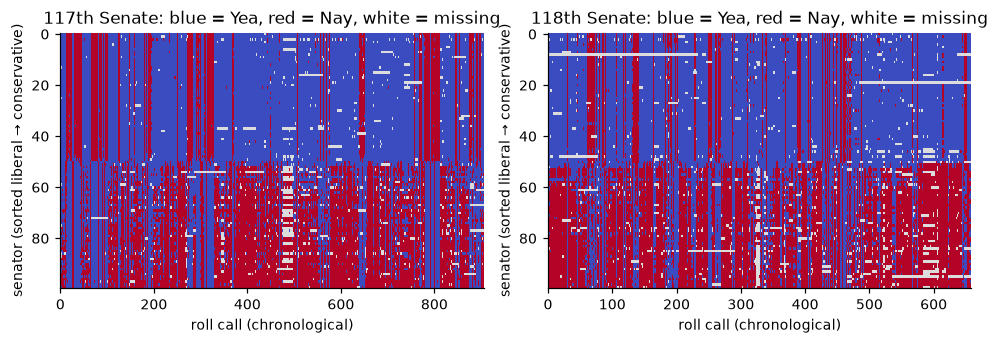

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, D in zip(axes, (D117, D118)):
    order = np.argsort(D['sen'].dim1.values)
    ax.imshow(D['X'][:, order].T, aspect='auto', cmap='coolwarm_r', vmin=-1, vmax=1, interpolation='nearest')
    ax.set_title(f"{D['congress']}th Senate: blue = Yea, red = Nay, white = missing")
    ax.set_xlabel('roll call (chronological)'); ax.set_ylabel('senator (sorted liberal → conservative)')
plt.tight_layout(); savefig('data_vote_matrix')

## 2. Model code

### M1: latent-class Naive Bayes
Each roll call $m$ has a hidden coalition type $Z^{(m)}\in\{1..K\}$; votes are independent given $Z$:
$P(z,\mathbf x)=\pi_z\prod_i \theta_{iz}^{[x_i=+1]}(1-\theta_{iz})^{[x_i=-1]}$, where missing votes simply drop
out of the product (they are marginalized). EM:
* E-step: $\gamma_{mk}=P(Z^{(m)}=k\mid \mathbf x_O^{(m)})\propto \pi_k\prod_{i\in O_m}P(x_{mi}\mid k)$;
* M-step (MAP with pseudo-counts $a,b$ on $\theta$ and $c$ on $\pi$):
  $\pi_k\propto\sum_m\gamma_{mk}+c_k$, $\;\theta_{ik}=\dfrac{\sum_m\gamma_{mk}[x_{mi}=+1]+a_{ik}}{\sum_m\gamma_{mk}[x_{mi}\neq0]+a_{ik}+b_{ik}}$.

With $a=b=c=1$ this is Laplace smoothing; in E4, $a=s\,\theta^{(117)}$, $b=s(1-\theta^{(117)})$ turns the 117th-Senate
parameters into a Beta prior of strength $s$. EM increases the penalized log-likelihood monotonically; we assert this.

In [4]:
def m1_terms(X, pi, theta):
    """log P(Z=k, x_O) for every roll call: shape (M, K)."""
    Y, Nn = (X == 1).astype(float), (X == -1).astype(float)
    return np.log(pi) + Y @ np.log(theta) + Nn @ np.log1p(-theta)

def m1_em(X, K, rng, a=1.0, b=1.0, c=1.0, init=None, fix_theta=False, max_iter=1000, tol=1e-8):
    Y, Nn = (X == 1).astype(float), (X == -1).astype(float)
    M, N = X.shape
    a, b = np.broadcast_to(a, (N, K)), np.broadcast_to(b, (N, K))
    c = np.broadcast_to(c, (K,))

    def mstep(g):
        pi = (g.sum(0) + c) / (M + c.sum())
        theta = (Y.T @ g + a) / ((Y + Nn).T @ g + a + b)
        return pi, theta

    if init is None:
        pi, theta = mstep(rng.dirichlet(np.ones(K), size=M))
    else:
        pi, theta = init['pi'].copy(), init['theta'].copy()
    theta0, trace = theta.copy(), []
    for it in range(max_iter):
        T = m1_terms(X, pi, theta)
        ll = logsumexp(T, axis=1)
        obj = ll.sum() + (c * np.log(pi)).sum() + (a * np.log(theta) + b * np.log1p(-theta)).sum()
        trace.append(obj)
        if it > 0 and obj - trace[-2] < tol * abs(obj):
            break
        pi, theta = mstep(np.exp(T - ll[:, None]))
        if fix_theta:
            theta = theta0
    trace = np.array(trace)
    assert np.all(np.diff(trace) > -1e-6 * abs(trace[-1])), 'EM objective decreased'
    return dict(pi=pi, theta=theta, trace=trace, K=K)

def m1_fit(X, K, rng, restarts=10, **kw):
    fits = [m1_em(X, K, rng, **kw) for _ in range(restarts)]
    return max(fits, key=lambda f: f['trace'][-1])

def m1_predict(model, Xe):
    T = m1_terms(Xe, model['pi'], model['theta'])
    g = np.exp(T - logsumexp(T, axis=1, keepdims=True))
    return g @ model['theta'].T            # P(X_i = Yea | x_O), exact

def m1_ll_per_vote(model, X):
    return logsumexp(m1_terms(X, model['pi'], model['theta']), axis=1).sum() / (X != 0).sum()

### M2: Chow-Liu tree Bayesian network
* **Structure:** the maximum-weight spanning tree on empirical mutual information $I(X_i;X_j)$ is the
  maximum-likelihood tree (Chow & Liu, 1968). MI is estimated from the roll calls where both senators voted
  (+1 pseudo-count per cell). We root it at the highest-degree senator and orient edges away from the root.
* **Parameters:** CPTs $P(x_i\mid x_{pa(i)})$ by MLE from available pairs (+1 Laplace), or by EM whose E-step computes
  exact node and (child, parent) posterior marginals with sum-product belief propagation.
* **Belief propagation** is vectorized over roll calls. Upward pass: $\beta_i=\lambda_i\prod_{c}m_{c\to i}$,
  $m_{i\to p}(x_p)=\sum_{x_i}P(x_i\mid x_p)\beta_i(x_i)$ (normalized; the log normalizers sum to $\log P(\mathbf x_O)$).
  Downward pass: $\alpha_i(x_i)=\sum_{x_p}P(x_i\mid x_p)\,\alpha_p(x_p)\beta_p(x_p)/m_{i\to p}(x_p)$; marginal $\propto\alpha_i\beta_i$.

State index 0 = Yea, 1 = Nay. `cpt[i, a_parent, a_child]`; for the root both rows hold its prior.

In [5]:
def pair_counts(X):
    """n[a_i, a_j, i, j] = #roll calls where senator i voted a_i and j voted a_j (0 = Yea, 1 = Nay)."""
    Y, Nn = (X == 1).astype(float), (X == -1).astype(float)
    return np.stack([np.stack([Y.T @ Y, Y.T @ Nn]), np.stack([Nn.T @ Y, Nn.T @ Nn])])

def mutual_information(X, alpha=1.0):
    p = pair_counts(X) + alpha
    p = p / p.sum((0, 1), keepdims=True)
    mi = (p * np.log(p / (p.sum(1, keepdims=True) * p.sum(0, keepdims=True)))).sum((0, 1))
    np.fill_diagonal(mi, 0)
    return mi

def max_spanning_tree(w):
    """Prim's algorithm, O(N^2)."""
    N = len(w)
    in_tree = np.zeros(N, bool); in_tree[0] = True
    best, link, edges = w[0].copy(), np.zeros(N, int), []
    for _ in range(N - 1):
        j = int(np.argmax(np.where(in_tree, -np.inf, best)))
        edges.append((int(link[j]), j)); in_tree[j] = True
        upd = (w[j] > best) & ~in_tree
        best[upd], link[upd] = w[j][upd], j
    return edges

def chow_liu(X, alpha=1.0):
    N = X.shape[1]
    mi = mutual_information(X, alpha)
    edges = max_spanning_tree(mi)
    root = int(np.argmax(np.bincount(np.array(edges).ravel(), minlength=N)))
    adj = [[] for _ in range(N)]
    for i, j in edges:
        adj[i].append(j); adj[j].append(i)
    parent, order, seen = -np.ones(N, int), [root], {root}
    for u in order:                                    # BFS: parents always precede children
        for w_ in adj[u]:
            if w_ not in seen:
                seen.add(w_); parent[w_] = u; order.append(w_)
    return dict(parent=parent, order=order, root=root, edges=edges, mi=mi)

def normalize_cpt(C):
    return C / C.sum(-1, keepdims=True)

def m2_counts_available(X, struct):
    n = pair_counts(X)
    C = np.zeros((X.shape[1], 2, 2))
    for i, p in enumerate(struct['parent']):
        if p < 0:
            C[i, :, 0], C[i, :, 1] = (X[:, i] == 1).sum(), (X[:, i] == -1).sum()
        else:
            C[i] = n[:, :, p, i]
    return C

def m2_bp(model, X):
    """Exact sum-product BP on the tree for every roll call. Returns node marginals (M,N,2),
    (parent, child) pair marginals (M,N,2,2) and log P(x_O) per roll call."""
    parent, order, cpt, root = model['parent'], model['order'], model['cpt'], model['root']
    M, N = X.shape
    beta = np.stack([X != -1, X != 1], axis=2).astype(float)       # evidence indicators lambda_i
    up = np.ones((M, N, 2))
    logZ = np.zeros(M)
    for i in reversed(order):                                       # children before parents
        s = beta[:, i].sum(1)
        beta[:, i] /= s[:, None]; logZ += np.log(s)
        if parent[i] >= 0:
            up[:, i] = beta[:, i] @ cpt[i].T
            beta[:, parent[i]] *= up[:, i]
    logZ += np.log(beta[:, root] @ cpt[root, 0])
    alpha = np.zeros((M, N, 2)); alpha[:, root] = cpt[root, 0]
    marg, pair = np.zeros((M, N, 2)), np.zeros((M, N, 2, 2))
    for i in order:
        p = parent[i]
        if p >= 0:
            outside = alpha[:, p] * beta[:, p] / up[:, i]           # parent belief without i's subtree
            a = outside @ cpt[i]
            alpha[:, i] = a / a.sum(1, keepdims=True)
            joint = outside[:, :, None] * cpt[i][None] * beta[:, i][:, None, :]
            pair[:, i] = joint / joint.sum((1, 2), keepdims=True)
        b = alpha[:, i] * beta[:, i]
        marg[:, i] = b / b.sum(1, keepdims=True)
    return marg, pair, logZ

def m2_log_prior(cpt, A, root):
    lp = A * np.log(cpt)
    return lp.sum() - lp[root, 1].sum()                             # root uses only one row

def m2_fit(X, struct=None, alpha=1.0, prior=None, em=True, max_iter=300, tol=1e-8):
    """prior: pseudo-count array (N,2,2); default = alpha everywhere (Laplace)."""
    struct = struct or chow_liu(X, alpha)
    N, root = X.shape[1], struct['root']
    A = np.full((N, 2, 2), alpha) if prior is None else prior
    model = dict(struct, cpt=normalize_cpt(m2_counts_available(X, struct) + A))
    trace = []
    if em:
        for it in range(max_iter):
            marg, pair, logZ = m2_bp(model, X)
            trace.append(logZ.sum() + m2_log_prior(model['cpt'], A, root))
            if it > 0 and trace[-1] - trace[-2] < tol * abs(trace[-1]):
                break
            C = pair.sum(0)
            C[root] = marg[:, root].sum(0)[None, :]
            model['cpt'] = normalize_cpt(C + A)
        assert np.all(np.diff(trace) > -1e-6 * abs(trace[-1])), 'EM objective decreased'
    model['trace'] = np.array(trace)
    return model

def m2_predict(model, Xe):
    return m2_bp(model, Xe)[0][:, :, 0]

def m2_ll_per_vote(model, X):
    return m2_bp(model, X)[2].sum() / (X != 0).sum()

### M3: sparse Ising model
$P(\mathbf x)\propto\exp(\sum_i\theta_ix_i+\sum_{i<j}W_{ij}x_ix_j)$, $x\in\{-1,+1\}$.

**Learning: $\ell_1$-regularized pseudo-likelihood.** With local field $h_i=\theta_i+\sum_jW_{ij}x_j$,
$P(x_i\mid\mathbf x_{-i})=\sigma(2x_ih_i)$. We minimize
$\frac1M\sum_m\sum_{i\in O_m}\log(1+e^{-2x_{mi}h_{mi}})+\lambda\sum_{i<j}|W_{ij}|$ jointly over $(\theta, W)$ with $W$ kept
symmetric (each pair is one parameter that enters both $h_i$ and $h_j$). The objective is convex; we use FISTA
(accelerated proximal gradient) with backtracking, where the proximal step is soft-thresholding. Missing neighbors
enter as $x_j=0$ (no evidence).

**Inference** of $P(X_i\mid\mathbf x_O)$ with observed votes clamped:
* Gibbs sampling, vectorized over roll calls and chains, with Rao-Blackwellized estimates (average of the
  conditional $\sigma(2h_i)$ instead of the 0/1 samples);
* naive mean-field: sequential coordinate updates $\mu_i\leftarrow\tanh(\theta_i+\sum_jW_{ij}\mu_j)$, which never
  increase the variational free energy and therefore converge;
* exact enumeration of all $2^n$ states for small $n$ (16 senators in E1).

In [6]:
def soft(x, t):
    return np.sign(x) * np.maximum(np.abs(x) - t, 0)

def ising_loss_grad(X, theta, W, grad=True):
    O = X != 0
    Xf = X.astype(float)
    z = 2 * Xf * (theta + Xf @ W)
    M = len(X)
    loss = (np.logaddexp(0, -z) * O).sum() / M
    if not grad:
        return loss
    r = 2 * Xf * expit(-z) * O / M                    # = -d loss / d h
    gW = -(Xf.T @ r + r.T @ Xf)
    np.fill_diagonal(gW, 0)
    return loss, -r.sum(0), gW

def ising_fit(X, lam, theta0=None, W0=None, max_iter=500, tol=1e-7):
    N = X.shape[1]
    if theta0 is None:
        p = ((X == 1).sum(0) + 1) / ((X != 0).sum(0) + 2)
        theta0 = 0.5 * np.log(p / (1 - p))
    th, W = theta0.copy(), (np.zeros((N, N)) if W0 is None else W0.copy())
    yth, yW, t, L = th.copy(), W.copy(), 1.0, 1.0
    F = lambda th_, W_: ising_loss_grad(X, th_, W_, grad=False) + lam * np.abs(W_).sum() / 2
    obj = [F(th, W)]
    for it in range(max_iter):
        f, gth, gW = ising_loss_grad(X, yth, yW)
        while True:                                           # backtracking line search
            th_n = yth - gth / L
            W_n = soft(yW - gW / L, lam / L); np.fill_diagonal(W_n, 0)
            dth, dW = th_n - yth, W_n - yW
            quad = f + gth @ dth + (gW * dW).sum() / 2 + L / 2 * (dth @ dth + (dW ** 2).sum() / 2)
            if ising_loss_grad(X, th_n, W_n, grad=False) <= quad + 1e-12:
                break
            L *= 2
        t_n = (1 + np.sqrt(1 + 4 * t * t)) / 2
        yth = th_n + (t - 1) / t_n * (th_n - th)
        yW = W_n + (t - 1) / t_n * (W_n - W)
        th, W, t = th_n, W_n, t_n
        obj.append(F(th, W))
        if abs(obj[-2] - obj[-1]) < tol * abs(obj[-1]):
            break
    return dict(theta=th, W=W, obj=np.array(obj), lam=lam)

def ising_pl_per_vote(model, X):
    """Held-out pseudo-log-likelihood per observed vote (higher is better)."""
    return -ising_loss_grad(X, model['theta'], model['W'], grad=False) * len(X) / (X != 0).sum()

def ising_gibbs(model, Xe, sweeps=300, burn=50, chains=4, rng=None, return_state=False):
    theta, W = model['theta'], model['W']
    U = Xe == 0
    S = np.repeat(Xe[None].astype(float), chains, axis=0)
    S[:, U] = rng.choice([-1.0, 1.0], size=(chains, U.sum()))
    H = theta + S @ W
    acc = np.zeros(S.shape)
    for s in range(sweeps):
        for i in range(len(theta)):
            p = expit(2 * H[..., i])
            if s >= burn:
                acc[..., i] += p
            new = np.where(U[:, i], np.where(rng.random(p.shape) < p, 1.0, -1.0), S[..., i])
            H += (new - S[..., i])[..., None] * W[i]
            S[..., i] = new
    P_chain = acc / max(sweeps - burn, 1)
    P = np.where(U, P_chain.mean(0), (Xe == 1).astype(float))
    if return_state:
        return P, S
    return P, P_chain

def ising_meanfield(model, Xe, max_iter=1000, tol=1e-6):
    theta, W = model['theta'], model['W']
    U = Xe == 0
    mu = Xe.astype(float)
    for it in range(max_iter):
        diff = 0.0
        for i in range(len(theta)):
            new = np.where(U[:, i], np.tanh(theta[i] + mu @ W[:, i]), mu[:, i])
            diff = max(diff, np.abs(new - mu[:, i]).max())
            mu[:, i] = new
        if diff < tol:
            break
    return (1 + mu) / 2, it + 1

def ising_exact(model, Xe):
    theta, W = model['theta'], model['W']
    n = len(theta)
    S = 1 - 2 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)          # all 2^n states
    logw = S @ theta + 0.5 * ((S @ W) * S).sum(1)
    nobs = (Xe != 0).sum(1)
    compat = (Xe @ S.T) == nobs[:, None]                                    # state agrees with evidence
    w = np.where(compat, np.exp(logw - logw.max()), 0.0)
    return (w @ (S == 1)) / w.sum(1, keepdims=True)

def ising_task_nll(model, X, seed=99):
    """Validation score that matches the prediction task: reveal 20% of the observed votes, predict the rest
    with mean-field, return NLL per hidden vote (lower is better)."""
    Xe, q = reveal(X, 0.2, np.random.default_rng(seed))
    return vote_metrics(ising_meanfield(model, Xe)[0], X, q)['nll']

### M4: hidden Markov model over roll calls
M1 treats roll calls as independent. M4 keeps M1's emission model but orders the roll calls by date and lets the
vote type follow a Markov chain: $Z_1\sim\pi$, $P(Z_t=k\mid Z_{t-1}=j)=A_{jk}$, and given $Z_t$ senators vote
independently with $P(X_{ti}=+1\mid Z_t=k)=\theta_{ik}$; missing votes drop out of the product, as in M1.
$P(\mathbf z,\mathbf x)=\pi_{z_1}\prod_{t>1}A_{z_{t-1}z_t}\prod_t\prod_{i\in O_t}P(x_{ti}\mid z_t)$.
With every row of $A$ equal to $\pi$, M4 reduces exactly to M1.

**Learning: EM (Baum-Welch), MAP version.** E-step by scaled forward-backward (each $\alpha_t$ is renormalized, so nothing underflows):
$\alpha_t(k)=P(\mathbf x_{1..t},Z_t{=}k)$, $\beta_t(k)=P(\mathbf x_{t+1..T}\mid Z_t{=}k)$, giving
$\gamma_{tk}\propto\alpha_t(k)\beta_t(k)$ and $\xi_t(j,k)\propto\alpha_t(j)A_{jk}P(\mathbf x_{t+1}\mid k)\beta_{t+1}(k)$.
M-step: $\pi_k\propto\gamma_{1k}+c_k$, $A_{jk}\propto\sum_t\xi_t(j,k)+d_{jk}$, and $\theta$ exactly as in M1 with
$\gamma_{tk}$ in place of $\gamma_{mk}$. The pseudo-counts $d_{jk}=d+\kappa[j{=}k]$ are a Dirichlet prior on each row of
$A$ ($\kappa>0$ makes it "sticky"). The penalized log-likelihood increases monotonically; we assert this.

**Inference.**
* Prediction is *filtering*: for roll call $t$, $P(Z_t\mid\mathbf x_{1..t-1},\mathbf x_{t,O})\propto
  P(Z_t\mid\mathbf x_{1..t-1})\,P(\mathbf x_{t,O}\mid Z_t)$ and $P(X_{ti}{=}+1\mid\cdot)=\sum_k P(Z_t{=}k\mid\cdot)\,\theta_{ik}$.
  Only earlier roll calls are used, never later ones; on test data the chain continues from the end of training.
* Validation score: $\log P(\mathbf x_{\text{val}}\mid\mathbf x_{\text{fit}})$ per vote, with the chain continuing from the
  fitting roll calls.
* Forward-backward smoothing ($\gamma$) and Viterbi decoding are used to interpret the learned sequence of vote types.

In [7]:
def hmm_emis(X, theta):
    """log P(x_O^{(t)} | Z_t = k) for every roll call: shape (T, K). Missing votes drop out, exactly as in M1."""
    Y, Nn = (X == 1).astype(float), (X == -1).astype(float)
    return Y @ np.log(theta) + Nn @ np.log1p(-theta)

def hmm_forward_backward(logB, pi, A):
    """Scaled forward-backward (Rabiner) on one chain. Each row of the emissions is shifted by its max before
    exponentiating, and alpha_t is renormalized to sum to one (scale c_t), so nothing under- or overflows.
    Returns log P(x_O), node posteriors gamma (T, K), expected transition counts sum_t xi_t (K, K),
    and the forward messages log alpha_t(k) = log P(x_1..t, Z_t = k)."""
    T, K = logB.shape
    mx = logB.max(1)
    B = np.exp(logB - mx[:, None])
    a, b, c = np.empty((T, K)), np.ones((T, K)), np.empty(T)
    a[0] = pi * B[0]
    for t in range(T):
        if t > 0:
            a[t] = (a[t - 1] @ A) * B[t]
        c[t] = a[t].sum(); a[t] /= c[t]                 # a_t = P(Z_t | x_1..t)
    for t in range(T - 2, -1, -1):
        b[t] = A @ (B[t + 1] * b[t + 1]) / c[t + 1]
    ll = np.log(c).sum() + mx.sum()
    gamma = a * b
    # sum_t xi_t(j, k) = sum_t P(Z_t = j, Z_{t+1} = k | x_O)
    xi = (a[:-1].T @ (B[1:] * b[1:] / c[1:, None])) * A
    with np.errstate(divide='ignore'):
        la = np.log(a) + np.cumsum(np.log(c) + mx)[:, None]
    return ll, gamma, xi, la

def hmm_em(X, K, rng, a=1.0, b=1.0, c=1.0, d=1.0, stick=0.0, init=None, max_iter=1000, tol=1e-8):
    """Baum-Welch (MAP) for an HMM over the date-ordered roll calls.
    Pseudo-counts: a, b on theta (as in M1), c on the initial distribution pi, and d + stick * I on each row of the
    transition matrix A (stick > 0 encourages staying in the same vote type)."""
    Y, Nn = (X == 1).astype(float), (X == -1).astype(float)
    T, N = X.shape
    a, b = np.broadcast_to(a, (N, K)), np.broadcast_to(b, (N, K))
    c = np.broadcast_to(c, (K,))
    dA = np.broadcast_to(d, (K, K)) + stick * np.eye(K)

    def mstep(g, xi):
        pi = (g[0] + c) / (1 + c.sum())
        A = (xi + dA) / (xi + dA).sum(1, keepdims=True)
        theta = (Y.T @ g + a) / ((Y + Nn).T @ g + a + b)
        return pi, A, theta

    if init is None:
        g0 = rng.dirichlet(np.ones(K), size=T)
        pi, A, theta = mstep(g0, rng.dirichlet(np.ones(K), size=K) * T / K)
    else:
        pi, A, theta = init['pi'].copy(), init['A'].copy(), init['theta'].copy()
    trace = []
    for it in range(max_iter):
        ll, g, xi, _ = hmm_forward_backward(hmm_emis(X, theta), pi, A)
        obj = (ll + (c * np.log(pi)).sum() + (dA * np.log(A)).sum()
               + (a * np.log(theta) + b * np.log1p(-theta)).sum())
        trace.append(obj)
        if it > 0 and obj - trace[-2] < tol * abs(obj):
            break
        pi, A, theta = mstep(g, xi)
    trace = np.array(trace)
    assert np.all(np.diff(trace) > -1e-6 * abs(trace[-1])), 'EM objective decreased'
    return dict(pi=pi, A=A, theta=theta, trace=trace, K=K)

def hmm_fit(X, K, rng, restarts=10, **kw):
    fits = [hmm_em(X, K, rng, **kw) for _ in range(restarts)]
    return max(fits, key=lambda f: f['trace'][-1])

def hmm_ll_per_vote(model, X):
    ll = hmm_forward_backward(hmm_emis(X, model['theta']), model['pi'], model['A'])[0]
    return ll / (X != 0).sum()

def hmm_cond_ll_per_vote(model, X_prev, X):
    """log P(x_O of X | X_prev) per observed vote in X: the chain continues from the end of X_prev (used for
    validation, where X follows the fitting roll calls in time)."""
    ll = lambda Z: hmm_forward_backward(hmm_emis(Z, model['theta']), model['pi'], model['A'])[0]
    return (ll(np.vstack([X_prev, X])) - ll(X_prev)) / (X != 0).sum()

def hmm_start(model, X_prev=None):
    """Predictive distribution P(Z_{T+1} | x_1..T) after filtering through the roll calls X_prev
    (e.g. the training sequence); the initial distribution pi if X_prev is None."""
    if X_prev is None or len(X_prev) == 0:
        return model['pi'].copy()
    la = hmm_forward_backward(hmm_emis(X_prev, model['theta']), model['pi'], model['A'])[3][-1]
    return np.exp(la - logsumexp(la)) @ model['A']

def hmm_predict(model, Xe, X_hist=None, X_prev=None, return_post=False):
    """Online (filtering) prediction of P(X_ti = Yea | evidence) on a sequence of roll calls.
    Row t is predicted from the evidence Xe[t] and the roll calls before it, never from later ones:
      prior_t = P(Z_t | x_1..t-1),  post_t ∝ prior_t * P(Xe[t] | Z_t),  P = post_t @ theta^T.
    After predicting row t, the filter is updated with X_hist[t] (the full observed votes of that roll call, i.e.
    the votes are revealed once it is over); with X_hist=None it is updated with the evidence Xe[t] only.
    X_prev (e.g. the training roll calls) are filtered first, so the chain continues from the end of training."""
    theta, A = model['theta'], model['A']
    X_hist = Xe if X_hist is None else X_hist
    lBe, lBh = hmm_emis(Xe, theta), hmm_emis(X_hist, theta)
    prior = np.log(hmm_start(model, X_prev))
    post = np.empty((len(Xe), len(prior)))
    for t in range(len(Xe)):
        p = prior + lBe[t]
        post[t] = np.exp(p - logsumexp(p))
        f = prior + lBh[t]
        prior = np.log(np.exp(f - logsumexp(f)) @ A)
    P = post @ theta.T
    return (P, post) if return_post else P

def hmm_viterbi(model, X):
    """Most likely sequence of vote types (max-product in log space)."""
    logB, logA = hmm_emis(X, model['theta']), np.log(model['A'])
    T, K = logB.shape
    delta, back = np.log(model['pi']) + logB[0], np.zeros((T, K), dtype=int)
    for t in range(1, T):
        s = delta[:, None] + logA
        back[t] = s.argmax(0)
        delta = s.max(0) + logB[t]
    z = np.empty(T, dtype=int); z[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        z[t - 1] = back[t, z[t]]
    return z

## 3. Correctness checks
Before touching real data we compare every inference routine against brute-force enumeration on small random
models, and check that EM / Chow-Liu recover known parameters from synthetic samples.

In [8]:
rng = np.random.default_rng(0)
n = 6
states = 1 - 2 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)       # +1 / -1
Xe_small = rng.choice([-1, 0, 0, 1], size=(20, n)).astype(np.int8)

def brute_marginals(logp_states, Xe):
    out = np.zeros(Xe.shape)
    for m, x in enumerate(Xe):
        ok = np.all((states == x) | (x == 0), axis=1)
        w = np.exp(logp_states[ok] - logp_states[ok].max())
        out[m] = (w @ (states[ok] == 1)) / w.sum()
    return out

# M1 vs enumeration
m1_toy = dict(pi=np.array([0.3, 0.7]), theta=rng.uniform(0.05, 0.95, (n, 2)))
lp = logsumexp(m1_terms(states, m1_toy['pi'], m1_toy['theta']), axis=1)
q = Xe_small == 0                                                         # queries = unobserved votes
err_m1 = np.abs(m1_predict(m1_toy, Xe_small) - brute_marginals(lp, Xe_small))[q].max()

# M2 (random tree) vs enumeration, including log P(x_O)
par = np.array([-1] + [int(rng.integers(0, i)) for i in range(1, n)])
cpt = rng.dirichlet([1, 1], size=(n, 2)); cpt[0, 1] = cpt[0, 0]
m2_toy = dict(parent=par, order=list(range(n)), root=0, cpt=cpt)
idx = (states == -1).astype(int)
lp = np.log(cpt[0, 0, idx[:, 0]]) + sum(np.log(cpt[i, idx[:, par[i]], idx[:, i]]) for i in range(1, n))
marg, _, logZ = m2_bp(m2_toy, Xe_small)
err_m2 = np.abs(marg[:, :, 0] - brute_marginals(lp, Xe_small)).max()
true_logZ = [logsumexp(lp[np.all((states == x) | (x == 0), axis=1)]) for x in Xe_small]
err_m2_Z = np.abs(logZ - true_logZ).max()

# Ising: exact enumeration vs brute force; Gibbs and mean-field errors on the same model
Wt = rng.normal(0, 0.4, (n, n)); Wt = np.triu(Wt, 1); Wt = Wt + Wt.T
ising_toy = dict(theta=rng.normal(0, 0.3, n), W=Wt)
lp = states @ ising_toy['theta'] + 0.5 * ((states @ Wt) * states).sum(1)
P_brute = brute_marginals(lp, Xe_small)
err_exact = np.abs(ising_exact(ising_toy, Xe_small) - P_brute).max()
err_gibbs = np.abs(ising_gibbs(ising_toy, Xe_small, 3000, 200, 4, rng)[0] - P_brute)[q].mean()
err_mf = np.abs(ising_meanfield(ising_toy, Xe_small)[0] - P_brute)[q].mean()

# M4 (HMM): forward-backward, filtering and Viterbi vs enumeration of all K^T state paths; reduction to M1
rng4 = np.random.default_rng(20)
T4, K4 = 6, 2
hmm_toy = dict(pi=rng4.dirichlet(np.ones(K4)), A=rng4.dirichlet(np.ones(K4), size=K4),
               theta=rng4.uniform(0.05, 0.95, (n, K4)))
X4 = rng4.choice([-1, 0, 0, 1], size=(T4, n)).astype(np.int8)
paths = np.array(list(itertools.product(range(K4), repeat=T4)))            # all K^T state sequences
lpath = np.log(hmm_toy['pi'])[paths[:, 0]] + np.log(hmm_toy['A'])[paths[:, :-1], paths[:, 1:]].sum(1)
lB4 = hmm_emis(X4, hmm_toy['theta'])
lp4 = lpath + lB4[np.arange(T4), paths].sum(1)                             # log P(z, x_O) per path
w4 = np.exp(lp4 - logsumexp(lp4))
ll4, g4, xi4, _ = hmm_forward_backward(lB4, hmm_toy['pi'], hmm_toy['A'])
g_brute = np.stack([np.bincount(paths[:, t], w4, K4) for t in range(T4)])
xi_brute = sum(np.bincount(paths[:, t] * K4 + paths[:, t + 1], w4, K4 * K4) for t in range(T4 - 1)).reshape(K4, K4)
err_hmm_ll = abs(ll4 - logsumexp(lp4))
err_hmm_post = max(np.abs(g4 - g_brute).max(), np.abs(xi4 - xi_brute).max())
# filtering: P(Z_t | full votes of roll calls 1..t-1, revealed votes of roll call t); later transitions sum to one
Xe4 = np.where(rng4.random(X4.shape) < 0.5, X4, 0).astype(np.int8)
_, post4 = hmm_predict(hmm_toy, Xe4, X_hist=X4, return_post=True)
lBe4 = hmm_emis(Xe4, hmm_toy['theta'])
err_hmm_filter = 0.0
for t in range(T4):
    lq = lpath + lB4[np.arange(t), paths[:, :t]].sum(1) + lBe4[t, paths[:, t]]
    pb = np.bincount(paths[:, t], np.exp(lq - logsumexp(lq)), K4)
    err_hmm_filter = max(err_hmm_filter, np.abs(pb - post4[t]).max())
err_hmm_vit = int((hmm_viterbi(hmm_toy, X4) != paths[lp4.argmax()]).sum())
m1_as_hmm = dict(pi=m1_toy['pi'], A=np.tile(m1_toy['pi'], (2, 1)), theta=m1_toy['theta'])   # every row of A = pi
err_hmm_m1 = max(abs(hmm_ll_per_vote(m1_as_hmm, Xe_small) - m1_ll_per_vote(m1_toy, Xe_small)),
                 np.abs(hmm_predict(m1_as_hmm, Xe_small) - m1_predict(m1_toy, Xe_small)).max())

checks = pd.DataFrame([
    ('M1 exact inference vs brute force (max abs, unobserved votes)', err_m1),
    ('M2 BP marginals vs brute force (max abs)', err_m2),
    ('M2 BP log P(x_O) vs brute force (max abs)', err_m2_Z),
    ('Ising exact enumeration vs brute force (max abs)', err_exact),
    ('Ising Gibbs, 3000 sweeps (mean abs)', err_gibbs),
    ('Ising mean-field (mean abs, approximation error)', err_mf),
    ('M4 forward-backward log P(x_O) vs enumeration of state paths (abs)', err_hmm_ll),
    ('M4 posteriors gamma, xi vs enumeration (max abs)', err_hmm_post),
    ('M4 filtering P(Z_t | past, evidence) vs enumeration (max abs)', err_hmm_filter),
    ('M4 Viterbi path vs best enumerated path (# mismatches)', err_hmm_vit),
    ('M4 with every row of A = pi vs M1 (max abs, log-lik and predictions)', err_hmm_m1)], columns=['check', 'error'])
assert err_m1 < 1e-10 and err_m2 < 1e-10 and err_m2_Z < 1e-10 and err_exact < 1e-10 and err_gibbs < 0.02
assert max(err_hmm_ll, err_hmm_post, err_hmm_filter, err_hmm_m1) < 1e-10 and err_hmm_vit == 0
checks

,check,error
0,"M1 exact inference vs brute force (max abs, un...",3.3307e-16
1,M2 BP marginals vs brute force (max abs),3.3307e-16
2,M2 BP log P(x_O) vs brute force (max abs),1.7764e-15
3,Ising exact enumeration vs brute force (max abs),4.4409e-16
4,"Ising Gibbs, 3000 sweeps (mean abs)",1.4251e-03
5,"Ising mean-field (mean abs, approximation error)",6.4214e-02
6,M4 forward-backward log P(x_O) vs enumeration ...,0.0000e+00
7,"M4 posteriors gamma, xi vs enumeration (max abs)",1.1102e-15
8,"M4 filtering P(Z_t | past, evidence) vs enumer...",5.5511e-16
9,M4 Viterbi path vs best enumerated path (# mis...,0.0000e+00


In [9]:
# Synthetic recovery: sample from a known M1 and a known tree, then learn them back.
rng = np.random.default_rng(1)
Ns, Ms = 30, 3000
true_pi, true_th = np.array([0.5, 0.3, 0.2]), rng.uniform(0.05, 0.95, (Ns, 3))
z = rng.choice(3, size=Ms, p=true_pi)
Xs = np.where(rng.random((Ms, Ns)) < true_th[:, z].T, 1, -1).astype(np.int8)
Xs_m, _ = mask_votes(Xs, 0.3, rng)                                   # also test EM with 30% missing
fit = m1_fit(Xs_m, 3, rng, restarts=5)
perm = min(itertools.permutations(range(3)), key=lambda p: np.abs(fit['theta'][:, p] - true_th).sum())
m1_rec_err = np.abs(fit['theta'][:, perm] - true_th).max()

par = np.array([-1] + [int(rng.integers(0, i)) for i in range(1, Ns)])
cpt = np.stack([rng.dirichlet([0.5, 0.5], size=2) for _ in range(Ns)]); cpt[0, 1] = cpt[0, 0]
Xt = np.zeros((Ms, Ns), int)
Xt[:, 0] = (rng.random(Ms) > cpt[0, 0, 0]).astype(int)
for i in range(1, Ns):
    Xt[:, i] = (rng.random(Ms) > cpt[i, Xt[:, par[i]], 0]).astype(int)
Xt = (1 - 2 * Xt).astype(np.int8)
learned = {frozenset(e) for e in chow_liu(Xt)['edges']}
true_edges = {frozenset((par[i], i)) for i in range(1, Ns)}
print(f'M1 EM with 30% missing: max |theta error| = {m1_rec_err:.3f}')
print(f'Chow-Liu recovered {len(learned & true_edges)}/{Ns - 1} true tree edges')

# M4: sample a sticky 3-state chain from a known HMM, hide 30% of the votes, learn it back with Baum-Welch.
rng4 = np.random.default_rng(21)
true_A = np.array([[0.8, 0.1, 0.1], [0.15, 0.7, 0.15], [0.2, 0.2, 0.6]])
zs = np.zeros(Ms, int); zs[0] = rng4.choice(3, p=true_pi)
for t in range(1, Ms):
    zs[t] = rng4.choice(3, p=true_A[zs[t - 1]])
Xh = np.where(rng4.random((Ms, Ns)) < true_th[:, zs].T, 1, -1).astype(np.int8)
Xh_m, _ = mask_votes(Xh, 0.3, rng4)
fit4 = hmm_fit(Xh_m, 3, rng4, restarts=5)
perm4 = list(min(itertools.permutations(range(3)), key=lambda p: np.abs(fit4['theta'][:, p] - true_th).sum()))
hmm_th_err = np.abs(fit4['theta'][:, perm4] - true_th).max()
hmm_A_err = np.abs(fit4['A'][np.ix_(perm4, perm4)] - true_A).max()
print(f'M4 Baum-Welch with 30% missing: max |theta error| = {hmm_th_err:.3f}, max |A error| = {hmm_A_err:.3f}')

M1 EM with 30% missing: max |theta error| = 0.050
Chow-Liu recovered 26/29 true tree edges


M4 Baum-Welch with 30% missing: max |theta error| = 0.053, max |A error| = 0.020


## 4. Model selection on real data
Roll calls are split chronologically into train (first 80%) and test (last 20%). Hyper-parameters are chosen on a
**validation** split, the last 20% of the *training* roll calls, so the test split is never used for any choice;
the selected models are then refit on the full training split.
* M1: number of coalition types $K\in\{2..8\}$ by validation log-likelihood per vote.
* M4: number of vote types $K\in\{4..10,12\}$ and transition stickiness $\kappa\in\{0,10,100\}$ jointly, by the same
  criterion as M1: validation log-likelihood per vote, $\log P(\mathbf x_{\text{val}}\mid\mathbf x_{\text{fit}})$, with the
  chain continuing from the fitting roll calls.
* M3: sparsity $\lambda$ by the **prediction task itself** on the validation split: reveal 20% of each validation roll
  call, predict the rest with mean-field, and take the $\lambda$ with the lowest NLL. (Our first version selected
  $\lambda$ by validation pseudo-likelihood; pseudo-likelihood scores predictions when all 99 other votes are known,
  which favours overly sparse graphs for a task where only 20% are revealed. Both scores are recorded below.)

In [10]:
rng = np.random.default_rng(2)
Ks = [2, 3, 4, 5, 6, 7, 8]
LAMS = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
sel_rows, best = [], {}
for D in (D117, D118):
    c = D['congress']
    Xtr, _ = split(D['X'])
    Xfit, Xval = split(Xtr)                       # validation = last 20% of the training roll calls
    for K in Ks:
        f = m1_fit(Xfit, K, rng, restarts=10)
        sel_rows.append(dict(congress=c, model='M1', param=K, train=m1_ll_per_vote(f, Xfit),
                             val=m1_ll_per_vote(f, Xval)))
    for lam in LAMS:
        f = ising_fit(Xfit, lam)
        party = D['sen'].party.values
        iu = np.triu_indices(len(party), 1)
        e = f['W'][iu] != 0
        sel_rows.append(dict(congress=c, model='M3', param=lam, train=ising_pl_per_vote(f, Xfit),
                             val=ising_pl_per_vote(f, Xval), val_task_nll=ising_task_nll(f, Xval), edges=int(e.sum()),
                             cross_party_frac=np.mean(party[iu[0]][e] != party[iu[1]][e]) if e.any() else np.nan))
K4S, KAPPAS = [4, 5, 6, 7, 8, 9, 10, 12], [0.0, 10.0, 100.0]
rng4 = np.random.default_rng(12)                  # separate generator, so the M1 / M3 selection above is unchanged
for D in (D117, D118):
    Xfit, Xval = split(split(D['X'])[0])
    for K in K4S:
        for kap in KAPPAS:
            f = hmm_fit(Xfit, K, rng4, restarts=10, stick=kap)
            sel_rows.append(dict(congress=D['congress'], model='M4', param=K, stick=kap,
                                 train=hmm_ll_per_vote(f, Xfit), val=hmm_cond_ll_per_vote(f, Xfit, Xval)))
sel = save_table(pd.DataFrame(sel_rows), 'model_selection')
for c in (117, 118):
    s = sel[sel.congress == c]
    best[c] = dict(K=int(s[s.model == 'M1'].sort_values('val').param.iloc[-1]),
                   lam=float(s[s.model == 'M3'].sort_values('val_task_nll').param.iloc[0]),
                   lam_pl=float(s[s.model == 'M3'].sort_values('val').param.iloc[-1]))
    s4 = s[s.model == 'M4'].sort_values('val').iloc[-1]
    best[c].update(K4=int(s4.param), stick=float(s4.stick))
print('selected:', best)
sel

selected: {117: {'K': 6, 'lam': 0.01, 'lam_pl': 0.05, 'K4': 12, 'stick': 0.0}, 118: {'K': 6, 'lam': 0.02, 'lam_pl': 0.05, 'K4': 12, 'stick': 0.0}}


,congress,model,param,train,val,val_task_nll,edges,cross_party_frac,stick
0,117,M1,2.0,-0.2546,-0.2748,NaN,NaN,NaN,NaN
1,117,M1,3.0,-0.1902,-0.1918,NaN,NaN,NaN,NaN
2,117,M1,4.0,-0.1731,-0.1722,NaN,NaN,NaN,NaN
3,117,M1,5.0,-0.1556,-0.1596,NaN,NaN,NaN,NaN
4,117,M1,6.0,-0.1501,-0.1569,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
71,118,M4,10.0,-0.1520,-0.2057,NaN,NaN,NaN,10.0
72,118,M4,10.0,-0.1543,-0.2091,NaN,NaN,NaN,100.0
73,118,M4,12.0,-0.1490,-0.2023,NaN,NaN,NaN,0.0
74,118,M4,12.0,-0.1476,-0.2050,NaN,NaN,NaN,10.0


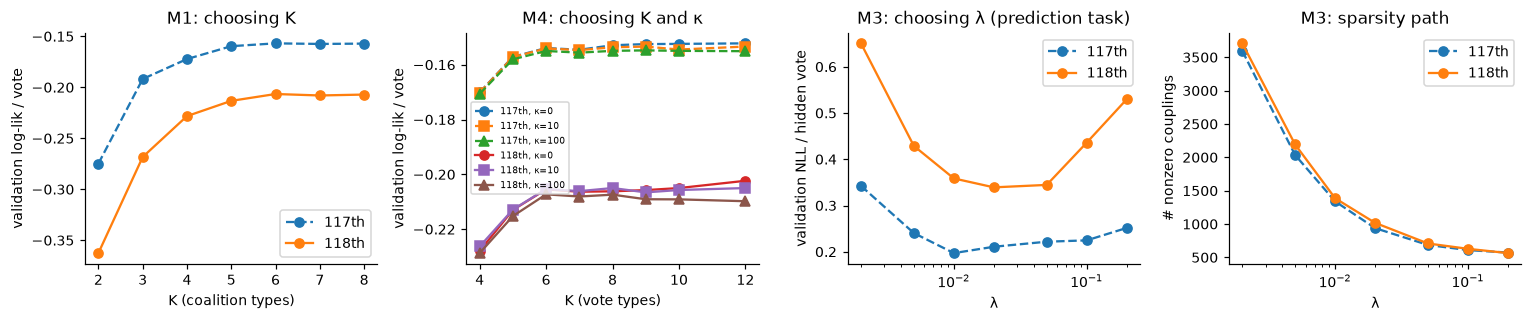

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for c, ls in ((117, '--'), (118, '-')):
    s = sel[(sel.congress == c) & (sel.model == 'M1')]
    axes[0].plot(s.param, s.val, ls, marker='o', label=f'{c}th')
    s = sel[(sel.congress == c) & (sel.model == 'M4')]
    for kap, mk in zip(KAPPAS, 'os^'):
        q = s[s.stick == kap]
        axes[1].plot(q.param, q.val, ls, marker=mk, label=f'{c}th, κ={kap:g}')
    s = sel[(sel.congress == c) & (sel.model == 'M3')]
    axes[2].semilogx(s.param, s.val_task_nll, ls, marker='o', label=f'{c}th')
    axes[3].semilogx(s.param, s.edges, ls, marker='o', label=f'{c}th')
axes[0].set(xlabel='K (coalition types)', ylabel='validation log-lik / vote', title='M1: choosing K')
axes[1].set(xlabel='K (vote types)', ylabel='validation log-lik / vote', title='M4: choosing K and κ')
axes[2].set(xlabel='λ', ylabel='validation NLL / hidden vote', title='M3: choosing λ (prediction task)')
axes[3].set(xlabel='λ', ylabel='# nonzero couplings', title='M3: sparsity path')
for ax in axes: ax.legend(fontsize=6 if ax is axes[1] else None)
plt.tight_layout(); savefig('model_selection')

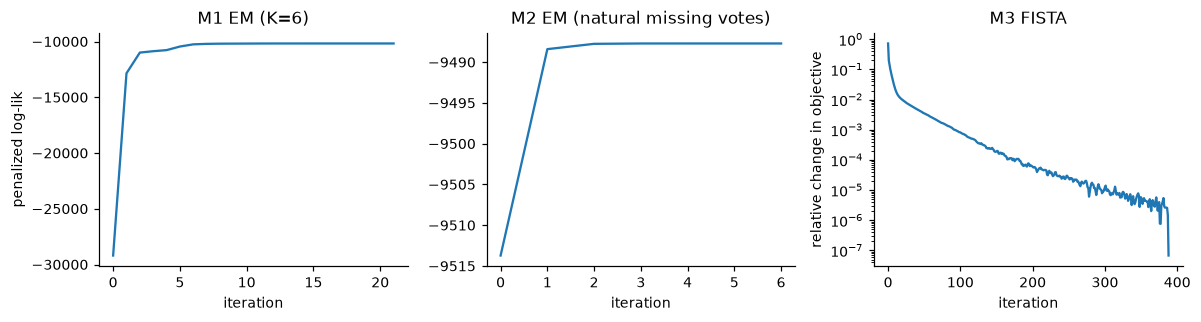

EM iterations: M1 22, M2 7; FISTA iterations 389, final relative change 6.8e-08, max over last 50 7.8e-06


In [12]:
# EM convergence curves on the 118th training data
Xtr118, Xte118 = split(D118['X'])
m1_118 = m1_fit(Xtr118, best[118]['K'], rng, restarts=10)
m2_118 = m2_fit(Xtr118)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(m1_118['trace']); axes[0].set(title=f"M1 EM (K={best[118]['K']})", xlabel='iteration',
                                           ylabel='penalized log-lik')
axes[1].plot(m2_118['trace']); axes[1].set(title='M2 EM (natural missing votes)', xlabel='iteration')
ising_118 = ising_fit(Xtr118, best[118]['lam'])
rel = np.abs(np.diff(ising_118['obj'])) / np.abs(ising_118['obj'][1:])
axes[2].semilogy(rel)
axes[2].set(title='M3 FISTA', xlabel='iteration', ylabel='relative change in objective')
plt.tight_layout(); savefig('convergence')
print(f"EM iterations: M1 {len(m1_118['trace'])}, M2 {len(m2_118['trace'])}; FISTA iterations {len(rel)}, "
      f"final relative change {rel[-1]:.1e}, max over last 50 {rel[-50:].max():.1e}")

## 5. Interpreting the learned models (118th Senate)
Party and NOMINATE scores are never used for training; they are only used here to interpret what was learned.

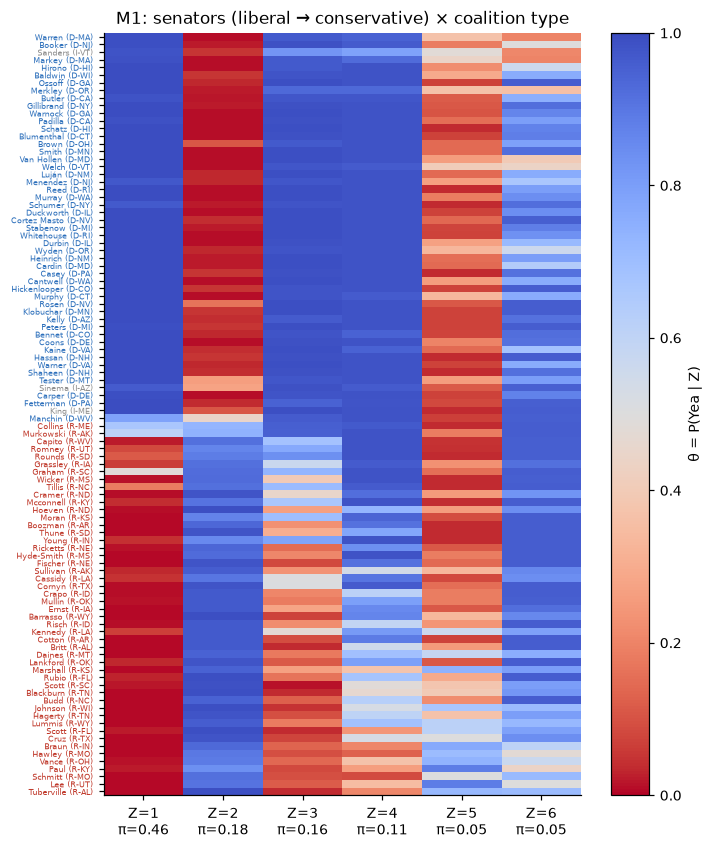

,Z=1,Z=2,Z=3,Z=4,Z=5,Z=6
row_0,,,,,,
On the Amendment,1,40,3,3,17,4
On the Cloture Motion,115,0,35,19,0,4
On the Joint Resolution,0,19,0,0,0,2
On the Motion,1,10,1,4,3,2
On the Motion to Table,4,10,0,0,2,1
On the Nomination,114,0,36,20,0,1
other,8,15,11,10,3,9


In [13]:
sen = D118['sen']
order = np.argsort(sen.dim1.values)
th = m1_118['theta']; cls = np.argsort(-m1_118['pi'])
fig, ax = plt.subplots(figsize=(4 + 0.5 * th.shape[1], 9))
im = ax.imshow(th[order][:, cls], aspect='auto', cmap='coolwarm_r', vmin=0, vmax=1)
ax.set_xticks(range(len(cls)), [f'Z={k + 1}\nπ={m1_118["pi"][j]:.2f}' for k, j in enumerate(cls)])
ax.set_yticks(range(len(order)), sen.label.values[order], fontsize=5)
for t, p in zip(ax.get_yticklabels(), sen.party.values[order]):
    t.set_color(PARTY_COLOR[p])
plt.colorbar(im, label='θ = P(Yea | Z)'); ax.set_title('M1: senators (liberal → conservative) × coalition type')
savefig('m1_theta_heatmap')

# which kinds of votes fall in each latent class?
T = m1_terms(Xtr118, m1_118['pi'], m1_118['theta'])
zhat = np.argmax(T, axis=1)
rank = {j: k + 1 for k, j in enumerate(cls)}
q = D118['rolls'].vote_question.iloc[:len(Xtr118)].fillna('other')
top_q = q.value_counts().index[:6]
ct = pd.crosstab(np.where(q.isin(top_q), q, 'other'), [rank[z] for z in zhat])
ct.columns = [f'Z={c}' for c in ct.columns]
ct.to_csv(f'{RES}/m1_class_by_vote_question.csv')
ct

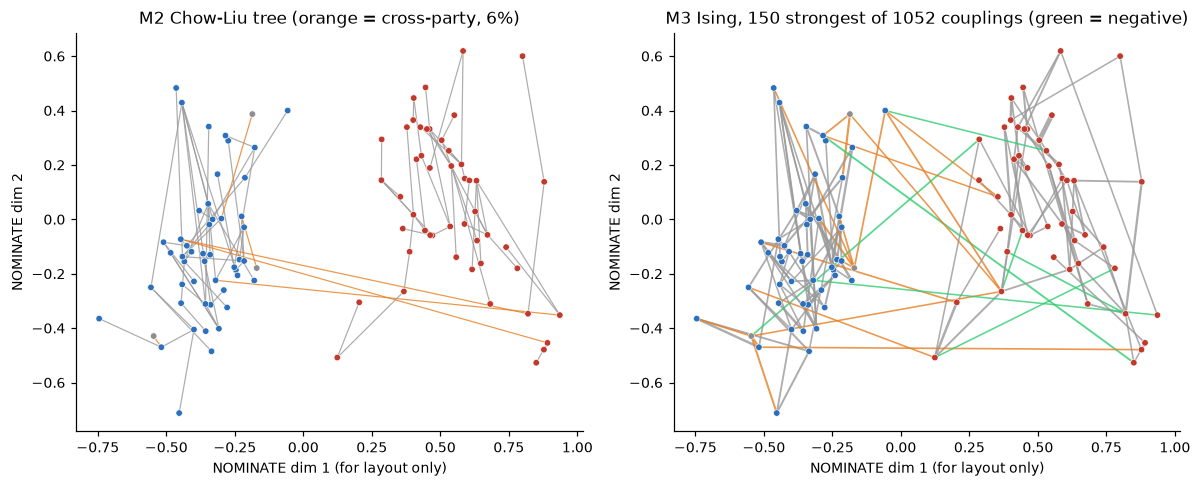

,statistic,value
0,tree root,Barrasso (R-WY)
1,tree max-degree senators,"Barrasso (R-WY), Warnock (D-GA), Duckworth (D-IL)"
2,tree cross-party edges,6/99
3,Ising edges,1052
4,Ising negative edges,284
5,Ising cross-party edge fraction,0.26


,senator_i,senator_j,W_ij
0,Crapo (R-ID),Risch (R-ID),1.9872
1,Reed (D-RI),Whitehouse (D-RI),1.3976
2,Blumenthal (D-CT),Schatz (D-HI),1.3098
3,Boozman (R-AR),Cotton (R-AR),0.9147
4,Carper (D-DE),Duckworth (D-IL),0.8995
5,Collins (R-ME),Murkowski (R-AK),0.8693
6,Cantwell (D-WA),Murray (D-WA),0.8619
7,Durbin (D-IL),Murphy (D-CT),0.8587
8,Heinrich (D-NM),Luján (D-NM),0.8558
9,Cramer (R-ND),Hoeven (R-ND),0.8528


In [14]:
def draw_graph(ax, sen, edges, weights=None, title=''):
    x, y = sen.dim1.values, sen.dim2.values
    party = sen.party.values
    for k, (i, j) in enumerate(edges):
        cross = party[i] != party[j]
        w = 1.0 if weights is None else weights[k]
        color = '#e67e22' if cross else '#999999'
        if weights is not None and w < 0:
            color = '#2ecc71'
        ax.plot([x[i], x[j]], [y[i], y[j]], color=color, lw=0.6 + 2.5 * min(abs(w), 1) if weights is not None else 0.8,
                alpha=0.8, zorder=1)
    ax.scatter(x, y, c=[PARTY_COLOR[p] for p in party], s=18, zorder=2, edgecolor='white', lw=0.4)
    ax.set(xlabel='NOMINATE dim 1 (for layout only)', ylabel='NOMINATE dim 2', title=title)

tree_edges = m2_118['edges']
party = sen.party.values
cross_tree = np.mean([party[i] != party[j] for i, j in tree_edges])
iu = np.triu_indices(len(sen), 1)
nz = ising_118['W'][iu] != 0
ising_edges = list(zip(iu[0][nz], iu[1][nz])); ising_w = ising_118['W'][iu][nz]
cross_ising = np.mean([party[i] != party[j] for i, j in ising_edges])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
draw_graph(axes[0], sen, tree_edges, title=f'M2 Chow-Liu tree (orange = cross-party, {cross_tree:.0%})')
strong = np.argsort(-np.abs(ising_w))[:150]
draw_graph(axes[1], sen, [ising_edges[k] for k in strong], ising_w[strong] / np.abs(ising_w).max(),
           title=f'M3 Ising, 150 strongest of {len(ising_edges)} couplings (green = negative)')
plt.tight_layout(); savefig('graphs_tree_ising')

deg = np.bincount(np.array(tree_edges).ravel(), minlength=len(sen))
top_edges = np.argsort(-np.abs(ising_w))[:10]
graph_stats = pd.DataFrame({
    'statistic': ['tree root', 'tree max-degree senators', 'tree cross-party edges', 'Ising edges',
                  'Ising negative edges', 'Ising cross-party edge fraction'],
    'value': [sen.label[m2_118['root']], ', '.join(sen.label.values[np.argsort(-deg)[:3]]),
              f'{sum(party[i] != party[j] for i, j in tree_edges)}/{len(tree_edges)}', len(ising_edges),
              int((ising_w < 0).sum()), f'{cross_ising:.2f}']})
strongest = pd.DataFrame([(sen.label[i], sen.label[j], w) for (i, j), w in
                          zip([ising_edges[k] for k in top_edges], ising_w[top_edges])],
                         columns=['senator_i', 'senator_j', 'W_ij'])
save_table(graph_stats, 'graph_stats'); save_table(strongest, 'ising_strongest_edges')
display(graph_stats); strongest

## 6. Experiments
### E1: exact vs. approximate inference
A 16-senator Ising model (8 Democrats and 8 Republicans spread evenly along NOMINATE dimension 1) is fit by the same
pseudo-likelihood method, so exact marginals are computable by enumerating $2^{16}=65{,}536$ states. On each held-out
roll call 4 of the 16 senators' votes are clamped as evidence and the other 12 are queried. We scale the couplings
$W\to\beta W$ to move from weak to strong interaction and measure each approximation's error against the exact marginals.

In [15]:
rng = np.random.default_rng(3)
def pick(party, k=8):
    s = sen[sen.party == party].sort_values('dim1')
    return list(s.index[np.linspace(0, len(s) - 1, k).round().astype(int)])
sub = pick('D') + pick('R')
Xtr16, Xte16 = Xtr118[:, sub], Xte118[:, sub]
Xfit16, Xval16 = split(Xtr16)
lam16 = min(LAMS, key=lambda l: ising_task_nll(ising_fit(Xfit16, l), Xval16))       # chosen on validation
ising16 = ising_fit(Xtr16, lam16)
Xe16 = np.zeros_like(Xte16)
for m in range(len(Xte16)):
    obs = np.flatnonzero(Xte16[m])
    k = rng.choice(obs, size=min(4, len(obs)), replace=False)
    Xe16[m, k] = Xte16[m, k]
Q = Xe16 == 0
print(f'16-senator model: λ = {lam16}, max |W| = {np.abs(ising16["W"]).max():.2f}, {len(Xe16)} roll calls')

def err(P, Pex):
    p, q = np.clip(Pex[Q], 1e-9, 1 - 1e-9), np.clip(P[Q], 1e-9, 1 - 1e-9)
    kl = p * np.log(p / q) + (1 - p) * np.log((1 - p) / (1 - q))
    return np.abs(P[Q] - Pex[Q]).mean(), kl.mean()

BETAS = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
SWEEPS = [10, 30, 100, 300, 1000]
e1 = []
for beta in BETAS:
    mdl = dict(theta=ising16['theta'], W=beta * ising16['W'])
    t0 = time.perf_counter(); Pex = ising_exact(mdl, Xe16); t_ex = time.perf_counter() - t0
    e1.append(dict(beta=beta, method='exact', sweeps=np.nan, l1=0.0, kl=0.0, seconds=t_ex))
    t0 = time.perf_counter(); Pmf, it = ising_meanfield(mdl, Xe16); t_mf = time.perf_counter() - t0
    e1.append(dict(beta=beta, method='mean-field', sweeps=it, **dict(zip(['l1', 'kl'], err(Pmf, Pex))), seconds=t_mf))
    for sw in SWEEPS:
        t0 = time.perf_counter()
        Pg, Pch = ising_gibbs(mdl, Xe16, sweeps=sw, burn=sw // 5, chains=4, rng=rng)
        dt = time.perf_counter() - t0
        e1.append(dict(beta=beta, method='Gibbs', sweeps=sw, **dict(zip(['l1', 'kl'], err(Pg, Pex))), seconds=dt,
                       chain_sd=Pch.std(0)[Q].mean()))
e1 = save_table(pd.DataFrame(e1), 'E1_inference')
e1[(e1.method != 'Gibbs') | (e1.sweeps == 300)].round(4)

16-senator model: λ = 0.2, max |W| = 0.74, 132 roll calls


,beta,method,sweeps,l1,kl,seconds,chain_sd
0,0.10,exact,NaN,0.0000,0.0000,0.1137,NaN
1,0.10,mean-field,6.0,0.0003,0.0000,0.0008,NaN
5,0.10,Gibbs,300.0,0.0006,0.0000,0.1394,0.0012
7,0.25,exact,NaN,0.0000,0.0000,0.0943,NaN
8,0.25,mean-field,8.0,0.0026,0.0000,0.0010,NaN
12,0.25,Gibbs,300.0,0.0014,0.0000,0.1424,0.0029
14,0.50,exact,NaN,0.0000,0.0000,0.0907,NaN
15,0.50,mean-field,12.0,0.0130,0.0007,0.0014,NaN
19,0.50,Gibbs,300.0,0.0027,0.0000,0.1360,0.0053
21,0.75,exact,NaN,0.0000,0.0000,0.0910,NaN


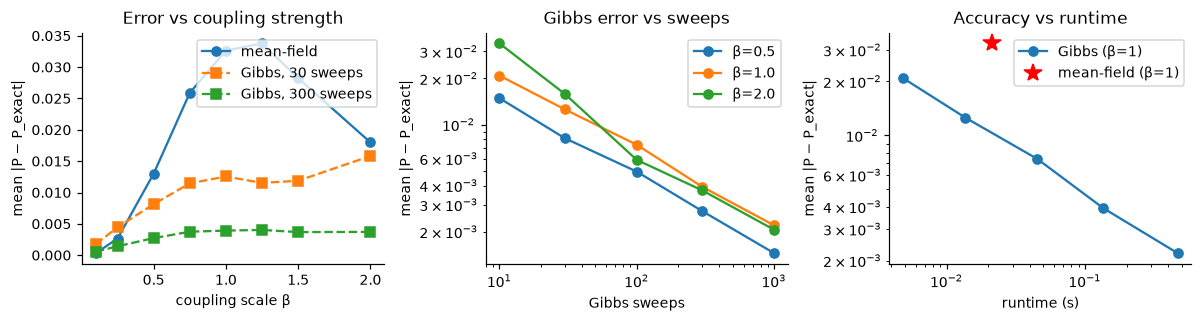

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
mf = e1[e1.method == 'mean-field']
axes[0].plot(mf.beta, mf.l1, 'o-', label='mean-field')
for sw in (30, 300):
    g = e1[(e1.method == 'Gibbs') & (e1.sweeps == sw)]
    axes[0].plot(g.beta, g.l1, 's--', label=f'Gibbs, {sw} sweeps')
axes[0].set(xlabel='coupling scale β', ylabel='mean |P − P_exact|', title='Error vs coupling strength'); axes[0].legend()
for beta in (0.5, 1.0, 2.0):
    g = e1[(e1.method == 'Gibbs') & (e1.beta == beta)]
    axes[1].loglog(g.sweeps, g.l1, 'o-', label=f'β={beta}')
axes[1].set(xlabel='Gibbs sweeps', ylabel='mean |P − P_exact|', title='Gibbs error vs sweeps'); axes[1].legend()
g = e1[(e1.method == 'Gibbs') & (e1.beta == 1.0)]
axes[2].loglog(g.seconds, g.l1, 'o-', label='Gibbs (β=1)')
m = mf[mf.beta == 1.0]
axes[2].loglog(m.seconds, m.l1, 'r*', ms=12, label='mean-field (β=1)')
axes[2].set(xlabel='runtime (s)', ylabel='mean |P − P_exact|', title='Accuracy vs runtime'); axes[2].legend()
plt.tight_layout(); savefig('E1_inference')

### E2: learning with missing data
We hide 10/30/50% of the observed training votes of the 118th Senate (3 random masks each) and compare:
* **M1 EM** (missing votes marginalized) vs **M1 imputed**: fill every missing vote with the senator's majority vote,
  then run EM as if the data were complete;
* **M2 available-case MLE** (CPTs counted from roll calls where both child and parent voted) vs **M2 EM**;
* **M3** with missing neighbors as $x_j=0$, and the stretch goal **M3 stochastic EM** (alternate one Gibbs sample of
  the missing votes given the current model with pseudo-likelihood refitting on the completed data).

Metrics: held-out log-likelihood per vote on the test roll calls (M1, M2 only; M3's partition function is intractable)
and imputation accuracy / AUC on the hidden training votes, predicted from the remaining votes of the same roll call.

In [17]:
def impute_majority(X):
    maj = np.where((X == 1).sum(0) >= (X == -1).sum(0), 1, -1)
    return np.where(X == 0, maj, X).astype(np.int8)

def ising_stochastic_em(X, lam, rounds=5, rng=None):
    mdl = ising_fit(X, lam)
    for _ in range(rounds):
        _, S = ising_gibbs(mdl, X, sweeps=30, burn=30, chains=1, rng=rng, return_state=True)
        mdl = ising_fit(S[0].astype(np.int8), lam, theta0=mdl['theta'], W0=mdl['W'])
    return mdl

rng = np.random.default_rng(4)
K118, lam118 = best[118]['K'], best[118]['lam']
e2 = []
for rate in (0.1, 0.3, 0.5):
    for seed in range(3):
        Xm, hide = mask_votes(Xtr118, rate, rng)
        struct = chow_liu(Xm)
        models = {
            'M1 EM': ('m1', m1_fit(Xm, K118, rng, restarts=5)),
            'M1 imputed': ('m1', m1_fit(impute_majority(Xm), K118, rng, restarts=5)),
            'M2 available-case MLE': ('m2', m2_fit(Xm, struct=struct, em=False)),
            'M2 EM': ('m2', m2_fit(Xm, struct=struct)),
            'M3 (x_j = 0)': ('m3', ising_fit(Xm, lam118)),
            'M3 stochastic EM': ('m3', ising_stochastic_em(Xm, lam118, rng=rng)),
        }
        for name, (kind, mdl) in models.items():
            if kind == 'm1':
                P, ll = m1_predict(mdl, Xm), m1_ll_per_vote(mdl, Xte118)
            elif kind == 'm2':
                P, ll = m2_predict(mdl, Xm), m2_ll_per_vote(mdl, Xte118)
            else:
                P, ll = ising_meanfield(mdl, Xm)[0], np.nan
            e2.append(dict(mask=rate, seed=seed, model=name, heldout_ll=ll, **vote_metrics(P, Xtr118, hide)))
e2 = save_table(pd.DataFrame(e2), 'E2_missing_raw')
e2_summary = e2.groupby(['model', 'mask'])[['heldout_ll', 'acc', 'auc', 'nll']].agg(['mean', 'std'])
e2_summary.to_csv(f'{RES}/E2_missing_summary.csv')
e2_summary.round(4)

heldout_ll             acc             auc          \
                                 mean     std    mean     std    mean     std   
model                 mask                                                      
M1 EM                 0.1     -0.1428  0.0032  0.9365  0.0023  0.9839  0.0008   
                      0.3     -0.1440  0.0012  0.9397  0.0023  0.9836  0.0009   
                      0.5     -0.1496  0.0011  0.9371  0.0003  0.9818  0.0005   
M1 imputed            0.1     -0.1407  0.0010  0.9354  0.0036  0.9810  0.0006   
                      0.3     -0.1619  0.0056  0.9200  0.0022  0.9698  0.0014   
                      0.5     -0.1843  0.0058  0.7817  0.0071  0.9186  0.0027   
M2 EM                 0.1     -0.1687  0.0024  0.9486  0.0035  0.9781  0.0030   
                      0.3     -0.1688  0.0089  0.9428  0.0014  0.9734  0.0003   
                      0.5     -0.1788  0.0052  0.9353  0.0014  0.9701  0.0004   
M2 available-case MLE 0.1     -0.1688  0.0030  0.9486  0.0034  0.9780  0.0028   
                      0.3     -0.1689  0.0085  0.9428  0.0012  0.9736  0.0003   
                      0.5     -0.1787  0.0064  0.9336  0.0016  0.9696  0.0004   
M3 (x_j = 0)          0.1         NaN     NaN  0.9585  0.0016  0.9928  0.0005   
                      0.3         NaN     NaN  0.9530  0.0015  0.9903  0.0010   
                      0.5         NaN     NaN  0.9395  0.0002  0.9851  0.0005   
M3 stochastic EM      0.1         NaN     NaN  0.9596  0.0007  0.9921  0.0004   
                      0.3         NaN     NaN  0.9552  0.0020  0.9897  0.0007   
                      0.5         NaN     NaN  0.9475  0.0011  0.9851  0.0007   

                               nll          
                              mean     std  
model                 mask                  
M1 EM                 0.1   0.1613  0.0046  
                      0.3   0.1614  0.0040  
                      0.5   0.1712  0.0010  
M1 imputed            0.1   0.1815  0.0015  
                      0.3   0.2374  0.0069  
                      0.5   0.3146  0.0040  
M2 EM                 0.1   0.1779  0.0136  
                      0.3   0.1926  0.0021  
                      0.5   0.2109  0.0033  
M2 available-case MLE 0.1   0.1778  0.0131  
                      0.3   0.1920  0.0027  
                      0.5   0.2113  0.0024  
M3 (x_j = 0)          0.1   0.1075  0.0047  
                      0.3   0.1390  0.0064  
                      0.5   0.2290  0.0035  
M3 stochastic EM      0.1   0.1091  0.0039  
                      0.3   0.1237  0.0039  
                      0.5   0.1487  0.0029

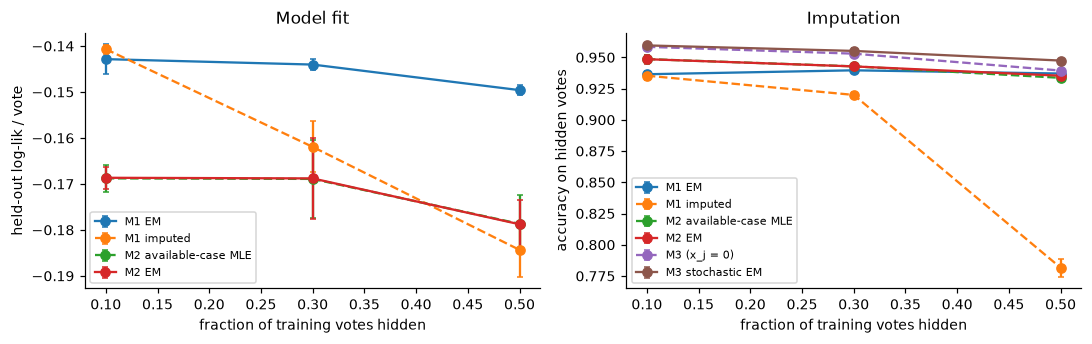

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for name in e2.model.unique():
    s = e2[e2.model == name].groupby('mask')
    ls = '--' if ('imputed' in name or 'available' in name or 'x_j' in name) else '-'
    if not e2[e2.model == name].heldout_ll.isna().all():
        axes[0].errorbar(s.heldout_ll.mean().index, s.heldout_ll.mean(), s.heldout_ll.std(), fmt='o' + ls, label=name,
                         capsize=2)
    axes[1].errorbar(s.acc.mean().index, s.acc.mean(), s.acc.std(), fmt='o' + ls, label=name, capsize=2)
axes[0].set(xlabel='fraction of training votes hidden', ylabel='held-out log-lik / vote', title='Model fit')
axes[1].set(xlabel='fraction of training votes hidden', ylabel='accuracy on hidden votes', title='Imputation')
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
plt.tight_layout(); savefig('E2_missing')

### E3: model comparison on vote prediction
On every held-out roll call we reveal a random 20% of the observed votes and predict the other 80%
(5 random reveals). Baselines: each senator's training Yea rate (no dependencies), and a **party-majority** baseline that
predicts each senator votes like the revealed members of their party (Independents grouped with Democrats, with whom they
caucus). The party baseline uses party labels, which the PGMs never see, so it is a reference point, not a competitor.

M4 is the only model that uses the order of roll calls. It predicts roll call $t$ by filtering, from the revealed votes
of $t$ and the full votes of all earlier roll calls (public once those votes are over), never from later ones. Because
that is extra information, a third baseline uses the same information: **previous roll call**, where each senator repeats
their last observed vote, with $P(\text{Yea})$ set by how often senators repeated their previous vote in training.

In [19]:
def e3_run(D, K, lam, K4, stick, seeds=5, rng=None):
    Xtr, Xte = split(D['X'])
    m1 = m1_fit(Xtr, K, rng, restarts=10)
    m2 = m2_fit(Xtr)
    m3 = ising_fit(Xtr, lam)
    m4 = hmm_fit(Xtr, K4, np.random.default_rng(13), restarts=10, stick=stick)   # own generator: reveals unchanged
    rate = ((Xtr == 1).sum(0) + 1) / ((Xtr != 0).sum(0) + 2)
    # previous roll call: each senator's last observed vote before roll call t (training roll calls come first)
    ffill_prev = lambda Z: pd.DataFrame(np.where(Z == 0, np.nan, Z)).ffill().shift(1).fillna(0).to_numpy()
    prev_tr = ffill_prev(Xtr.astype(float))
    repeat = np.mean(Xtr[(Xtr != 0) & (prev_tr != 0)] == prev_tr[(Xtr != 0) & (prev_tr != 0)])
    prev_te = ffill_prev(np.vstack([Xtr, Xte]).astype(float))[len(Xtr):]
    prev_P = np.where(prev_te == 0, rate, np.where(prev_te == 1, repeat, 1 - repeat))
    caucus = np.where(D['sen'].party.values == 'R', 1, 0)
    rows = []
    for seed in range(seeds):
        Xe, query = reveal(Xte, 0.2, rng)
        party_P = np.zeros(Xe.shape)
        for g in (0, 1):
            cols = caucus == g
            yea, nay = (Xe[:, cols] == 1).sum(1), (Xe[:, cols] == -1).sum(1)
            party_P[:, cols] = ((yea + 0.5) / (yea + nay + 1))[:, None]
        t = {}
        preds = {'per-senator rate': np.broadcast_to(rate, Xe.shape),
                 'party majority (uses labels)': party_P,
                 'previous roll call': prev_P}
        t0 = time.perf_counter(); preds['M1 latent class'] = m1_predict(m1, Xe); t['M1 latent class'] = time.perf_counter() - t0
        t0 = time.perf_counter(); preds['M2 Chow-Liu tree'] = m2_predict(m2, Xe); t['M2 Chow-Liu tree'] = time.perf_counter() - t0
        t0 = time.perf_counter(); preds['M3 Ising, Gibbs'] = ising_gibbs(m3, Xe, 300, 50, 4, rng)[0]; t['M3 Ising, Gibbs'] = time.perf_counter() - t0
        t0 = time.perf_counter(); preds['M3 Ising, mean-field'] = ising_meanfield(m3, Xe)[0]; t['M3 Ising, mean-field'] = time.perf_counter() - t0
        t0 = time.perf_counter(); preds['M4 HMM (filtering)'] = hmm_predict(m4, Xe, X_hist=Xte, X_prev=Xtr); t['M4 HMM (filtering)'] = time.perf_counter() - t0
        for name, P in preds.items():
            rows.append(dict(congress=D['congress'], seed=seed, model=name, seconds=t.get(name, 0.0),
                             **vote_metrics(P, Xte, query)))
    return rows, dict(m1=m1, m2=m2, m3=m3, m4=m4)

rng = np.random.default_rng(5)
e3, e3_models = [], {}
for D in (D117, D118):
    b = best[D['congress']]
    rows, e3_models[D['congress']] = e3_run(D, b['K'], b['lam'], b['K4'], b['stick'], rng=rng)
    e3 += rows
e3 = save_table(pd.DataFrame(e3), 'E3_comparison_raw')
model_order = list(e3.model.unique())
e3_summary = (e3.groupby(['congress', 'model'])[['acc', 'nll', 'auc', 'seconds']].mean()
                .reindex(pd.MultiIndex.from_product([[117, 118], model_order])))
e3_summary.to_csv(f'{RES}/E3_comparison_summary.csv')
e3_summary.round(4)

acc     nll     auc  seconds
117 per-senator rate              0.6545  0.6535  0.6608   0.0000
    party majority (uses labels)  0.9108  0.2353  0.9659   0.0000
    previous roll call            0.7453  0.5750  0.7401   0.0000
    M1 latent class               0.9340  0.1699  0.9810   0.0004
    M2 Chow-Liu tree              0.9301  0.1998  0.9735   0.0074
    M3 Ising, Gibbs               0.9297  0.1938  0.9794   2.6292
    M3 Ising, mean-field          0.9289  0.2424  0.9756   0.1356
    M4 HMM (filtering)            0.9343  0.1657  0.9823   0.0290
118 per-senator rate              0.8730  0.4453  0.8999   0.0000
    party majority (uses labels)  0.9486  0.1692  0.9824   0.0000
    previous roll call            0.8846  0.4201  0.8835   0.0000
    M1 latent class               0.9447  0.1363  0.9888   0.0003
    M2 Chow-Liu tree              0.9471  0.1647  0.9801   0.0058
    M3 Ising, Gibbs               0.9493  0.1515  0.9858   1.9484
    M3 Ising, mean-field          0.9456  0.1867  0.9811   0.0753
    M4 HMM (filtering)            0.9490  0.1300  0.9897   0.0187

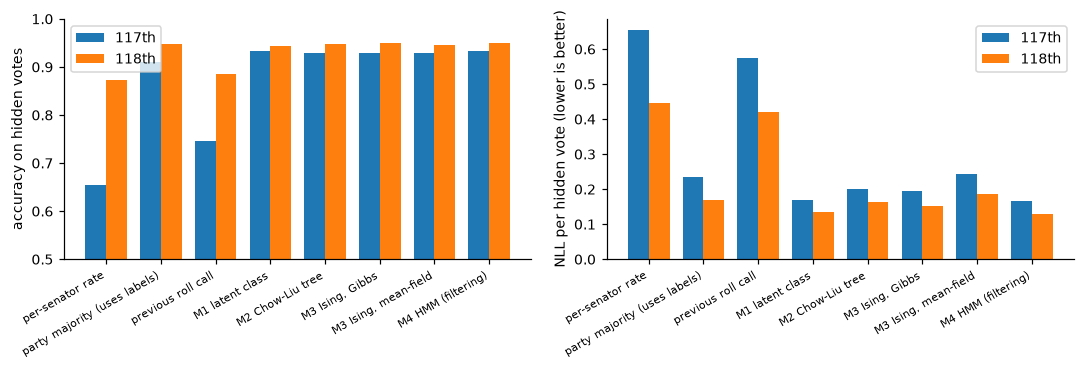

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
w = 0.38
for k, c in enumerate((117, 118)):
    s = e3_summary.loc[c]
    xs = np.arange(len(s)) + (k - 0.5) * w
    axes[0].bar(xs, s.acc, w, label=f'{c}th'); axes[1].bar(xs, s.nll, w, label=f'{c}th')
for ax, lab in zip(axes, ('accuracy on hidden votes', 'NLL per hidden vote (lower is better)')):
    ax.set_xticks(range(len(model_order)), model_order, rotation=30, ha='right', fontsize=7)
    ax.set_ylabel(lab); ax.legend()
axes[0].set_ylim(0.5, 1)
plt.tight_layout(); savefig('E3_comparison')

#### Why is M3 not better? Inference vs. model selection
Two checks on the same reveals: (i) 10x more Gibbs sweeps, to see whether the sampler had not mixed; (ii) the M3 model
that pseudo-likelihood selection would have chosen, to see how much the selection criterion matters.

In [21]:
rng = np.random.default_rng(10)
diag = []
for D in (D117, D118):
    c = D['congress']
    Xtr, Xte = split(D['X'])
    m3_task = e3_models[c]['m3']
    m3_pl = ising_fit(Xtr, best[c]['lam_pl'])
    for seed in range(3):
        Xe, query = reveal(Xte, 0.2, np.random.default_rng(100 + seed))
        cands = {f"λ={best[c]['lam']} (task), Gibbs 300": ising_gibbs(m3_task, Xe, 300, 50, 4, rng)[0],
                 f"λ={best[c]['lam']} (task), Gibbs 3000": ising_gibbs(m3_task, Xe, 3000, 500, 4, rng)[0],
                 f"λ={best[c]['lam_pl']} (pseudo-lik), Gibbs 300": ising_gibbs(m3_pl, Xe, 300, 50, 4, rng)[0],
                 f"λ={best[c]['lam_pl']} (pseudo-lik), mean-field": ising_meanfield(m3_pl, Xe)[0]}
        for name, P in cands.items():
            diag.append(dict(congress=c, model=name, **vote_metrics(P, Xte, query)))
diag = pd.DataFrame(diag).groupby(['congress', 'model'], sort=False)[['acc', 'nll']].mean().reset_index()
save_table(diag.round(4), 'E3_ising_diagnostic')

,congress,model,acc,nll
0,117,"λ=0.01 (task), Gibbs 300",0.9302,0.1858
1,117,"λ=0.01 (task), Gibbs 3000",0.9317,0.1897
2,117,"λ=0.05 (pseudo-lik), Gibbs 300",0.9115,0.2332
3,117,"λ=0.05 (pseudo-lik), mean-field",0.8864,0.3386
4,118,"λ=0.02 (task), Gibbs 300",0.9490,0.1480
5,118,"λ=0.02 (task), Gibbs 3000",0.9480,0.1503
6,118,"λ=0.05 (pseudo-lik), Gibbs 300",0.9431,0.1543
7,118,"λ=0.05 (pseudo-lik), mean-field",0.9347,0.2006


In [22]:
# Where do the models fail? Accuracy on the 118th test roll calls, split by how partisan each vote was.
rng = np.random.default_rng(6)
Xe, query = reveal(Xte118, 0.2, rng)
mdl = e3_models[118]
preds = {'M1': m1_predict(mdl['m1'], Xe), 'M2': m2_predict(mdl['m2'], Xe), 'M3 (MF)': ising_meanfield(mdl['m3'], Xe)[0]}
party = sen.party.values
d_yes = (Xte118[:, party != 'R'] == 1).mean(1) / (Xte118[:, party != 'R'] != 0).mean(1)
r_yes = (Xte118[:, party == 'R'] == 1).mean(1) / (Xte118[:, party == 'R'] != 0).mean(1)
split_votes = np.abs(d_yes - r_yes) < 0.5                        # parties not sharply opposed
rows = []
for name, P in preds.items():
    for lab, sel_rc in (('party-line roll calls', ~split_votes), ('cross-cutting roll calls', split_votes)):
        q = query & sel_rc[:, None]
        rows.append(dict(model=name, subset=lab, n_rollcalls=int(sel_rc.sum()), acc=np.mean((P[q] > 0.5) == (Xte118[q] == 1))))
save_table(pd.DataFrame(rows), 'E3_by_vote_type')

,model,subset,n_rollcalls,acc
0,M1,party-line roll calls,112,0.9652
1,M1,cross-cutting roll calls,20,0.8379
2,M2,party-line roll calls,112,0.9666
3,M2,cross-cutting roll calls,20,0.8340
4,M3 (MF),party-line roll calls,112,0.9686
5,M3 (MF),cross-cutting roll calls,20,0.8327


#### Error analysis: which senators and which roll calls are hard?
Per-senator accuracy on hidden votes (118th test roll calls, 5 random reveals) shows whether errors are spread
evenly or concentrated on particular senators. We then look at the single test roll call where M1 is least accurate.

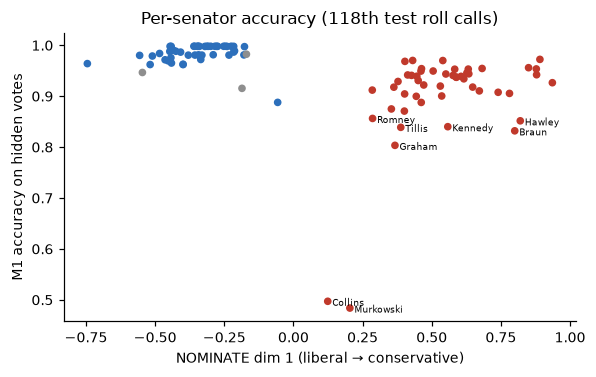

,label,party,dim1,M1,M2,M3 (MF),n_votes
58,Murkowski (R-AK),R,0.204,0.484,0.611,0.654,130
16,Collins (R-ME),R,0.124,0.497,0.603,0.645,132
32,Graham (R-SC),R,0.367,0.804,0.642,0.546,129
9,Braun (R-IN),R,0.800,0.832,0.863,0.860,99
89,Tillis (R-NC),R,0.388,0.839,0.864,0.855,122
48,Kennedy (R-LA),R,0.558,0.840,0.852,0.857,122
42,Hawley (R-MO),R,0.820,0.852,0.884,0.922,122
73,Romney (R-UT),R,0.286,0.856,0.872,0.880,96
23,Cramer (R-ND),R,0.401,0.871,0.869,0.866,113
71,Rounds (R-SD),R,0.354,0.875,0.891,0.919,109


date                                                     2024-11-20
question                                 On the Motion to Discharge
description       A joint resolution providing for congressional...
yea                                                              17
nay                                                              79
M1_accuracy                                                   0.683
assigned_class                                 Z=5 (posterior 1.00)
mean_pred_yea                     {'D': 0.16, 'R': 0.31, 'I': 0.21}
yea_by_party                {'D': '15/46', 'R': '0/47', 'I': '2/3'}
mispredicted      Cruz (R-TX), Durbin (D-IL), Daines (R-MT), Hir...
dtype: object

In [23]:
rng = np.random.default_rng(8)
correct = {k: np.zeros(Xte118.shape) for k in ('M1', 'M2', 'M3 (MF)')}
count = np.zeros(Xte118.shape)
for _ in range(5):
    Xe, query = reveal(Xte118, 0.2, rng)
    P = {'M1': m1_predict(mdl['m1'], Xe), 'M2': m2_predict(mdl['m2'], Xe), 'M3 (MF)': ising_meanfield(mdl['m3'], Xe)[0]}
    for k in correct:
        correct[k] += query * ((P[k] > 0.5) == (Xte118 == 1))
    count += query
per_sen = sen[['label', 'party', 'dim1']].copy()
for k in correct:
    per_sen[k] = correct[k].sum(0) / np.maximum(count.sum(0), 1)
per_sen['n_votes'] = (Xte118 != 0).sum(0)
per_sen = per_sen[per_sen.n_votes > 0].sort_values('M1')        # drop senators absent from the test period
save_table(per_sen.round(4), 'E3_per_senator')

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(per_sen.dim1, per_sen['M1'], c=[PARTY_COLOR[p] for p in per_sen.party], s=16)
for _, r in per_sen.head(8).iterrows():
    ax.annotate(r.label.split(' (')[0], (r.dim1, r['M1']), fontsize=6, xytext=(3, -3), textcoords='offset points')
ax.set(xlabel='NOMINATE dim 1 (liberal → conservative)', ylabel='M1 accuracy on hidden votes',
       title='Per-senator accuracy (118th test roll calls)')
savefig('E3_per_senator')
display(per_sen.head(10).round(3))

# hardest roll call for M1
acc_rc = correct['M1'].sum(1) / np.maximum(count.sum(1), 1)
hard = int(np.argmin(acc_rc))
rc = D118['rolls'].iloc[len(Xtr118) + hard]
x = Xte118[hard]
Xe1, _ = reveal(Xte118[hard:hard + 1], 0.2, np.random.default_rng(9))
P_rev = m1_predict(mdl['m1'], Xe1)[0]
g = np.exp(m1_terms(Xe1, mdl['m1']['pi'], mdl['m1']['theta']))[0]; g /= g.sum()
wrong = (x != 0) & ((P_rev > 0.5) != (x == 1))
case = dict(date=rc.date, question=rc.vote_question, description=rc.vote_desc, yea=int((x == 1).sum()),
            nay=int((x == -1).sum()), M1_accuracy=round(float(acc_rc[hard]), 3),
            assigned_class=f"Z={list(np.argsort(-mdl['m1']['pi'])).index(int(np.argmax(g))) + 1} (posterior {g.max():.2f})",
            mean_pred_yea={p: round(float(P_rev[party == p].mean()), 2) for p in ('D', 'R', 'I')},
            yea_by_party={p: f"{int(((x == 1) & (party == p)).sum())}/{int(((x != 0) & (party == p)).sum())}"
                          for p in ('D', 'R', 'I')},
            mispredicted=', '.join(sen.label.values[wrong][:15]))
pd.Series(case).to_csv(f'{RES}/E3_hardest_rollcall.csv')
pd.Series(case)

### E4: cross-Congress transfer (117th → 118th)
Only senators who served (and passed the presence filter) in both Congresses are used. All conditions are evaluated on
the same 118th test roll calls with the E3 reveal-20% task (3 reveals) and the held-out log-likelihood.
* **in-Congress**: trained on the 118th training split (upper reference);
* **direct transfer**: trained on all 117th roll calls, no 118th data;
* **M1 refit π**: keep the 117th $\theta$ (senators' positions per coalition type), re-estimate only the coalition mix $\pi$
  on 118th data;
* **Bayesian transfer**: the 117th parameters become Beta/Dirichlet pseudo-counts of strength $s$ and are updated with the
  first $n$ 118th roll calls; compared with learning from the same $n$ roll calls with only Laplace smoothing.

In [24]:
common = sorted(set(D117['sen'].bioguide) & set(D118['sen'].bioguide))
col117 = D117['sen'].set_index('bioguide').index.get_indexer(common)
col118 = D118['sen'].set_index('bioguide').index.get_indexer(common)
A117 = D117['X'][:, col117]
A_tr, A_te = Xtr118[:, col118], Xte118[:, col118]
print(f'{len(common)} senators in both Congresses; 117th: {len(A117)} roll calls, 118th train/test: {len(A_tr)}/{len(A_te)}')

rng = np.random.default_rng(7)
K, lam = best[117]['K'], best[117]['lam']
reveals = [reveal(A_te, 0.2, rng) for _ in range(3)]

def evaluate(name, kind, mdl, n_train=None, s=None):
    out = []
    for Xe, q in reveals:
        P = m1_predict(mdl, Xe) if kind == 'm1' else m2_predict(mdl, Xe) if kind == 'm2' else ising_meanfield(mdl, Xe)[0]
        out.append(vote_metrics(P, A_te, q))
    ll = m1_ll_per_vote(mdl, A_te) if kind == 'm1' else m2_ll_per_vote(mdl, A_te) if kind == 'm2' else np.nan
    r = pd.DataFrame(out).mean().to_dict()
    return dict(condition=name, model=kind.upper(), n_118=n_train, s=s, heldout_ll=ll, **r)

m1_117 = m1_fit(A117, K, rng); m2_117 = m2_fit(A117); m3_117 = ising_fit(A117, lam)
m1_in = m1_fit(A_tr, K, rng); m2_in = m2_fit(A_tr); m3_in = ising_fit(A_tr, lam)
e4 = [evaluate('in-Congress (118 train)', 'm1', m1_in, len(A_tr)),
      evaluate('direct transfer (117)', 'm1', m1_117, 0),
      evaluate('117 θ, refit π on 118', 'm1', m1_em(A_tr, K, rng, init=m1_117, fix_theta=True), len(A_tr)),
      evaluate('in-Congress (118 train)', 'm2', m2_in, len(A_tr)),
      evaluate('direct transfer (117)', 'm2', m2_117, 0),
      evaluate('in-Congress (118 train)', 'm3', m3_in, len(A_tr)),
      evaluate('direct transfer (117)', 'm3', m3_117, 0)]
e4_main = save_table(pd.DataFrame(e4), 'E4_transfer')
e4_main.round(4)

91 senators in both Congresses; 117th: 906 roll calls, 118th train/test: 527/132


,condition,model,n_118,s,heldout_ll,acc,nll,auc
0,in-Congress (118 train),M1,527,None,-0.1440,0.9449,0.1396,0.9878
1,direct transfer (117),M1,0,None,-0.1479,0.9450,0.1430,0.9873
2,"117 θ, refit π on 118",M1,527,None,-0.1468,0.9455,0.1413,0.9874
3,in-Congress (118 train),M2,527,None,-0.1714,0.9436,0.1718,0.9794
4,direct transfer (117),M2,0,None,-0.1718,0.9452,0.1674,0.9821
5,in-Congress (118 train),M3,527,None,NaN,0.9452,0.2003,0.9809
6,direct transfer (117),M3,0,None,NaN,0.9527,0.1753,0.9838


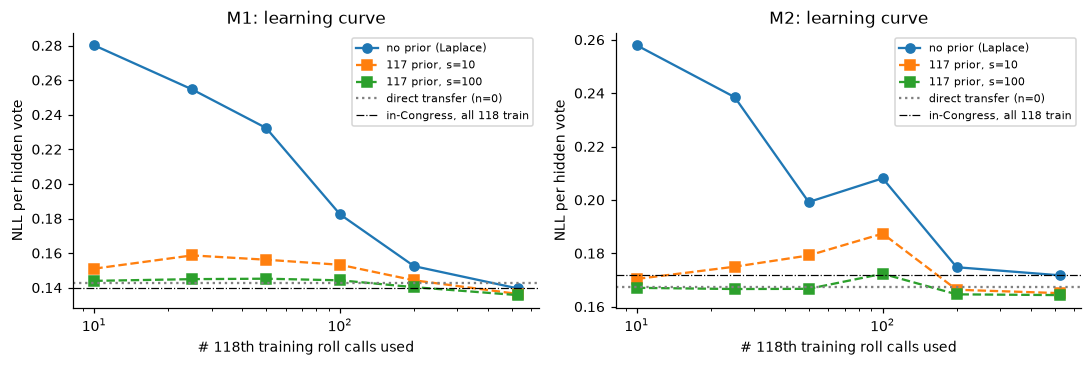

In [25]:
NS = [10, 25, 50, 100, 200, len(A_tr)]
STRENGTHS = [10, 100]
curve = []
for n_ in NS:
    Xn = A_tr[:n_]
    curve.append(evaluate('no prior', 'm1', m1_fit(Xn, K, rng, restarts=5), n_))
    curve.append(evaluate('no prior', 'm2', m2_fit(Xn), n_))
    for s in STRENGTHS:
        th0, pi0 = m1_117['theta'], m1_117['pi']
        m1p = m1_em(Xn, K, rng, a=s * th0, b=s * (1 - th0), c=s * pi0, init=m1_117)
        curve.append(evaluate('117 prior', 'm1', m1p, n_, s))
        prior = s * m2_117['cpt']
        m2p = m2_fit(Xn, struct={k: m2_117[k] for k in ('parent', 'order', 'root', 'edges', 'mi')}, prior=prior)
        curve.append(evaluate('117 prior', 'm2', m2p, n_, s))
curve = save_table(pd.DataFrame(curve), 'E4_learning_curve')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, kind in zip(axes, ('M1', 'M2')):
    c = curve[curve.model == kind]
    s0 = c[c.condition == 'no prior']; ax.semilogx(s0.n_118, s0.nll, 'o-', label='no prior (Laplace)')
    for s in STRENGTHS:
        sp = c[(c.condition == '117 prior') & (c.s == s)]; ax.semilogx(sp.n_118, sp.nll, 's--', label=f'117 prior, s={s}')
    ref = e4_main[e4_main.model == kind].set_index('condition').nll
    ax.axhline(ref['direct transfer (117)'], color='gray', ls=':', label='direct transfer (n=0)')
    ax.axhline(ref['in-Congress (118 train)'], color='k', ls='-.', lw=0.8, label='in-Congress, all 118 train')
    ax.set(xlabel='# 118th training roll calls used', ylabel='NLL per hidden vote', title=f'{kind}: learning curve')
    ax.legend(fontsize=7)
plt.tight_layout(); savefig('E4_transfer_curve')

## 7. Summary of results

In [26]:
print(f'total runtime: {(time.time() - T_START) / 60:.1f} min\n')
print('Data:'); display(pd.read_csv(f'{RES}/data_summary.csv'))
print('Selected hyper-parameters:', best)
print('\nE1 (mean |error| vs exact, Gibbs at 300 sweeps):')
display(e1[(e1.method == 'mean-field') | ((e1.method == 'Gibbs') & (e1.sweeps == 300))]
        .pivot(index='beta', columns='method', values='l1').round(4))
print('E2 (means over 3 masks):')
display(e2.groupby(['mask', 'model'])[['heldout_ll', 'acc', 'auc']].mean().unstack(0).round(4))
print('E3:'); display(e3_summary[['acc', 'nll', 'auc']].round(4))
print('E4:'); display(e4_main[['condition', 'model', 'heldout_ll', 'acc', 'nll']].round(4))

total runtime: 7.7 min

Data:


,congress,roll_calls_raw,roll_calls_kept,senators,missing_rate,R,D,I
0,117,949,906,100,0.0389,50,48,2
1,118,691,659,100,0.0521,49,48,3


Selected hyper-parameters: {117: {'K': 6, 'lam': 0.01, 'lam_pl': 0.05, 'K4': 12, 'stick': 0.0}, 118: {'K': 6, 'lam': 0.02, 'lam_pl': 0.05, 'K4': 12, 'stick': 0.0}}

E1 (mean |error| vs exact, Gibbs at 300 sweeps):


method,Gibbs,mean-field
beta,,
0.10,0.0006,0.0003
0.25,0.0014,0.0026
0.50,0.0027,0.0130
0.75,0.0037,0.0259
1.00,0.0039,0.0326
1.25,0.0040,0.0338
1.50,0.0037,0.0282
2.00,0.0037,0.0180


E2 (means over 3 masks):


heldout_ll                     acc                  \
mask                         0.1     0.3     0.5     0.1     0.3     0.5   
model                                                                      
M1 EM                    -0.1428 -0.1440 -0.1496  0.9365  0.9397  0.9371   
M1 imputed               -0.1407 -0.1619 -0.1843  0.9354  0.9200  0.7817   
M2 EM                    -0.1687 -0.1688 -0.1788  0.9486  0.9428  0.9353   
M2 available-case MLE    -0.1688 -0.1689 -0.1787  0.9486  0.9428  0.9336   
M3 (x_j = 0)                 NaN     NaN     NaN  0.9585  0.9530  0.9395   
M3 stochastic EM             NaN     NaN     NaN  0.9596  0.9552  0.9475   

                          auc                  
mask                      0.1     0.3     0.5  
model                                          
M1 EM                  0.9839  0.9836  0.9818  
M1 imputed             0.9810  0.9698  0.9186  
M2 EM                  0.9781  0.9734  0.9701  
M2 available-case MLE  0.9780  0.9736  0.9696  
M3 (x_j = 0)           0.9928  0.9903  0.9851  
M3 stochastic EM       0.9921  0.9897  0.9851

E3:


acc     nll     auc
117 per-senator rate              0.6545  0.6535  0.6608
    party majority (uses labels)  0.9108  0.2353  0.9659
    previous roll call            0.7453  0.5750  0.7401
    M1 latent class               0.9340  0.1699  0.9810
    M2 Chow-Liu tree              0.9301  0.1998  0.9735
    M3 Ising, Gibbs               0.9297  0.1938  0.9794
    M3 Ising, mean-field          0.9289  0.2424  0.9756
    M4 HMM (filtering)            0.9343  0.1657  0.9823
118 per-senator rate              0.8730  0.4453  0.8999
    party majority (uses labels)  0.9486  0.1692  0.9824
    previous roll call            0.8846  0.4201  0.8835
    M1 latent class               0.9447  0.1363  0.9888
    M2 Chow-Liu tree              0.9471  0.1647  0.9801
    M3 Ising, Gibbs               0.9493  0.1515  0.9858
    M3 Ising, mean-field          0.9456  0.1867  0.9811
    M4 HMM (filtering)            0.9490  0.1300  0.9897

E4:


,condition,model,heldout_ll,acc,nll
0,in-Congress (118 train),M1,-0.1440,0.9449,0.1396
1,direct transfer (117),M1,-0.1479,0.9450,0.1430
2,"117 θ, refit π on 118",M1,-0.1468,0.9455,0.1413
3,in-Congress (118 train),M2,-0.1714,0.9436,0.1718
4,direct transfer (117),M2,-0.1718,0.9452,0.1674
5,in-Congress (118 train),M3,NaN,0.9452,0.2003
6,direct transfer (117),M3,NaN,0.9527,0.1753
